# Classificação da Qualidade de Vinhos (WineQT)

## Objetivo

Desenvolver um modelo de classificação capaz de prever se um vinho é de **alta qualidade** a partir de suas características físico-químicas.

**Etapas do desafio**
| Seção | Conteúdo |
|---|---|
| 1 | Compreensão do problema |
| 2 | Análise Exploratória de Dados (distribuições, correlações, outliers/inconsistências, balanceamento) |
| 3 | Pré-processamento (padronização, feature engineering) |
| 4 | Desenvolvimento de modelos |
| 5 | Avaliação e comparação dos modelos |
| 6 | Interpretação dos resultados (variáveis mais influentes e implicações para a produção) |
| 7 | Conclusões, limitações e próximos passos |

## Configuração

In [1]:
# Importação das bibliotecas principais
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import (
    PartialDependenceDisplay,
    permutation_importance,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
SEED = 42

# Paleta inspirada em vinho
BORDO = "#6D071A"          # vinho tinto – cor principal
TINTO = "#9E2A3A"          # tinto mais claro
VERDE_GARRAFA = "#2F4F3E"  # garrafa
DOURADO = "#C9A227"        # vinho branco
CORTICA = "#C8B49A"        # rolha – tom neutro
ROSE_CLARO = "#F6E3E6"     # rosé bem claro
TEXTO = "#2B1A1D"          # quase preto, puxado para o vinho

CORES = [CORTICA, BORDO]  # 0 = baixa/média | 1 = alta
CORES_MODELOS = {
    "Regressão Logística": DOURADO,
    "SVM": VERDE_GARRAFA,
    "Random Forest": BORDO,
}
CMAP_DIV = LinearSegmentedColormap.from_list(
    "vinho_div", [VERDE_GARRAFA, "#ffffff", BORDO]
)
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "vinho_seq", ["#ffffff", ROSE_CLARO, BORDO]
)

sns.set_theme(style="whitegrid", rc={
    "text.color": TEXTO,
    "axes.labelcolor": TEXTO,
    "axes.titlecolor": TEXTO,
    "axes.edgecolor": CORTICA,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
})

# Etapa 1 – Compreensão do problema 

### 1.1 Contexto

A avaliação de qualidade de vinhos é feita tradicionalmente por especialistas (análise sensorial) – um processo **subjetivo, demorado e dependente da experiência** do avaliador. A ideia aqui é usar dados físico-químicos medidos durante a produção para **antecipar** se um vinho tende a ser de alta qualidade, se tornando uma ferramenta para apoiar enólogos e veniculas a identificar quais fatores químicos mais influenciam a percepção de qualidade.

**Variável alvo:** `quality` (nota de 0 a 10 dada por especialistas) será transformada em uma variável **binária**:

| Classe | Regra | Rótulo |
|---|---|---|
| Alta qualidade | `quality ≥ 7` | **1** |
| Baixa/Média qualidade | `quality < 7` | **0** |

**Tipo de problema:** classificação supervisionada binária.
**Variáveis preditoras:** 11 medidas físico-químicas. A coluna `Id` é apenas um identificador e será removida da base de dados.

### 1.2 Variáveis

| Variável | Significado enológico |
|---|---|
| `fixed acidity` (acidez fixa) | Estrutura, frescor e longevidade |
| `volatile acidity` (acidez volátil) | Sanidade microbiológica e oxidação ("virando vinagre") |
| `citric acid` (ácido cítrico) | Frescor adicional e notas frutadas |
| `residual sugar` (açúcar residual) | Doçura percebida e corpo |
| `chlorides` (cloretos) | Salinidade e equilíbrio gustativo |
| `free sulfur dioxide` (SO₂ livre) | Fração do conservante ativa contra bactérias e oxidação |
| `total sulfur dioxide` (SO₂ total) | Carga total de conservantes |
| `density` (densidade) | Sensação de peso (relação entre álcool e açúcar) |
| `pH` | Força real da acidez; estabilidade microbiológica |
| `sulphates` (sulfatos) | Influenciam longevidade e níveis de SO₂ |
| `alcohol` (teor alcoólico) | Volume, calor em boca e leveza |
| `quality` (qualidade) | Nota atribuída por especialistas (equilíbrio, harmonia, ausência de defeitos) |

### 1.3 Limpeza inicial e variável alvo 

In [2]:
# Carregando o Dataset
df = pd.read_csv("../data/WineQT.csv")
print("Base original:", df.shape)
df.head()

Base original: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
# Remoção da coluna Id
df = df.drop(columns=["Id"])

# Transformação da nota em classificação binária
df["alta_qualidade"] = (df["quality"] >= 7).astype(int)

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alta_qualidade
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [4]:
# Definição das variáveis de entrada (features) e saída (target)

FEATURES = [c for c in df.columns if c not in ("quality", "alta_qualidade")]
TARGET = "alta_qualidade"

# Etapa 2 – Análise Exploratória de Dados (EDA)

### 2.1 Visão geral e estatísticas descritivas

In [5]:
# Informações detalhadas do DataFrame

print("Visão geral do DataFrame:")
df.info()

Visão geral do DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  alta_qualidade        1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [6]:
# Verificação de valores nulos

print("Valores nulos por coluna:")
df.isnull().sum()

Valores nulos por coluna:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
alta_qualidade          0
dtype: int64

In [7]:
# Verificação de duplicatas
print("Duplicatas:", df.duplicated().sum())
df[df.duplicated()]

Duplicatas: 125


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alta_qualidade
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
46,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5,0
64,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.99720,2.93,1.95,9.9,6,0
65,7.7,0.490,0.26,1.90,0.062,9.0,31.0,0.99660,3.39,0.64,9.6,5,0
71,8.1,0.545,0.18,1.90,0.080,13.0,35.0,0.99720,3.30,0.59,9.0,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1076,7.5,0.380,0.57,2.30,0.106,5.0,12.0,0.99605,3.36,0.55,11.4,6,0
1113,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,0
1114,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,0
1116,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5,0


In [8]:
# Remoção de duplicatas
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1018, 13)

In [9]:
# Verificação de estatísticas descritivas do DataFrame
df.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,1018.0,0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,1018.0,0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,1018.0,2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,1018.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1018.0,15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1018.0,46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,1018.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1018.0,3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,1018.0,0.657,0.168,0.330,0.550,0.620,0.720,2.000


**O que isso significa**
- A base está **completa**: nenhuma dado nulo faltando.
- **125 vinhos repetidos (11%) foram removidos.** Assim o mesmo vinho não é usado para treinar e depois para testar o modelo.
- As medidas estão em **escalas diferentes** (a densidade fica perto de 1, o SO₂ total chega a 289). Isso será ajustado antes de treinar os modelos.
- Açúcar, cloretos, SO₂ total e sulfatos têm alguns valores **acima do normal**, serão analisados na seção 2.6.

### 2.2 Balanceamento das classes

alta_qualidade
0    0.865
1    0.135
Name: proportion, dtype: float64

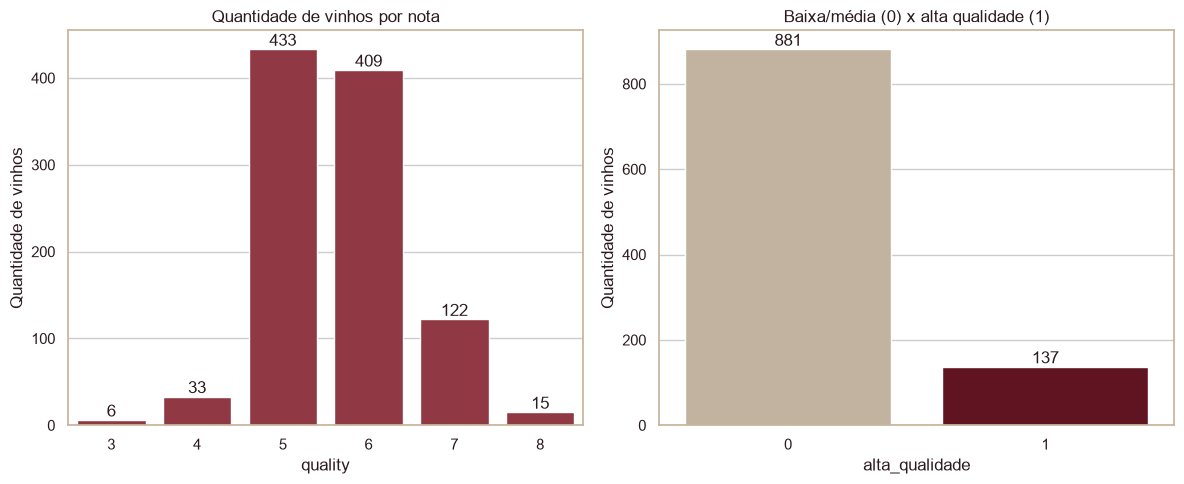

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x="quality", data=df, color=TINTO, ax=ax[0])
sns.countplot(x=TARGET, data=df, palette=CORES, ax=ax[1])
ax[0].set_title("Quantidade de vinhos por nota")
ax[1].set_title("Baixa/média (0) x alta qualidade (1)")
for eixo in ax:
    for barras in eixo.containers:
        eixo.bar_label(barras)
    eixo.set_ylabel("Quantidade de vinhos")
plt.tight_layout()

df[TARGET].value_counts(normalize=True).round(3)

**13,5% dos vinhos** (137 de 1.018) são considerados de alta qualidade (Nota ≥7). A maioria recebeu nota 5 ou 6.

**O que isso significa:** um modelo "preguiçoso" que dissesse que todo vinho é de média/baixa qualidade acertaria 86% das vezes, sem encontrar nenhum vinho bom. Por isso:
- o sucesso será medido pela capacidade de **encontrar os vinhos bons**, e não pelo total de acertos;
- os modelos serão configurados para **dar mais atenção aos vinhos de alta qualidade**, que são menos comun.

### 2.3 Distribuição das variáveis

,assimetria
chlorides,5.93
residual sugar,4.35
sulphates,2.42
total sulfur dioxide,1.68
free sulfur dioxide,1.17
fixed acidity,1.04
alcohol,0.85
volatile acidity,0.72
citric acid,0.37
pH,0.26


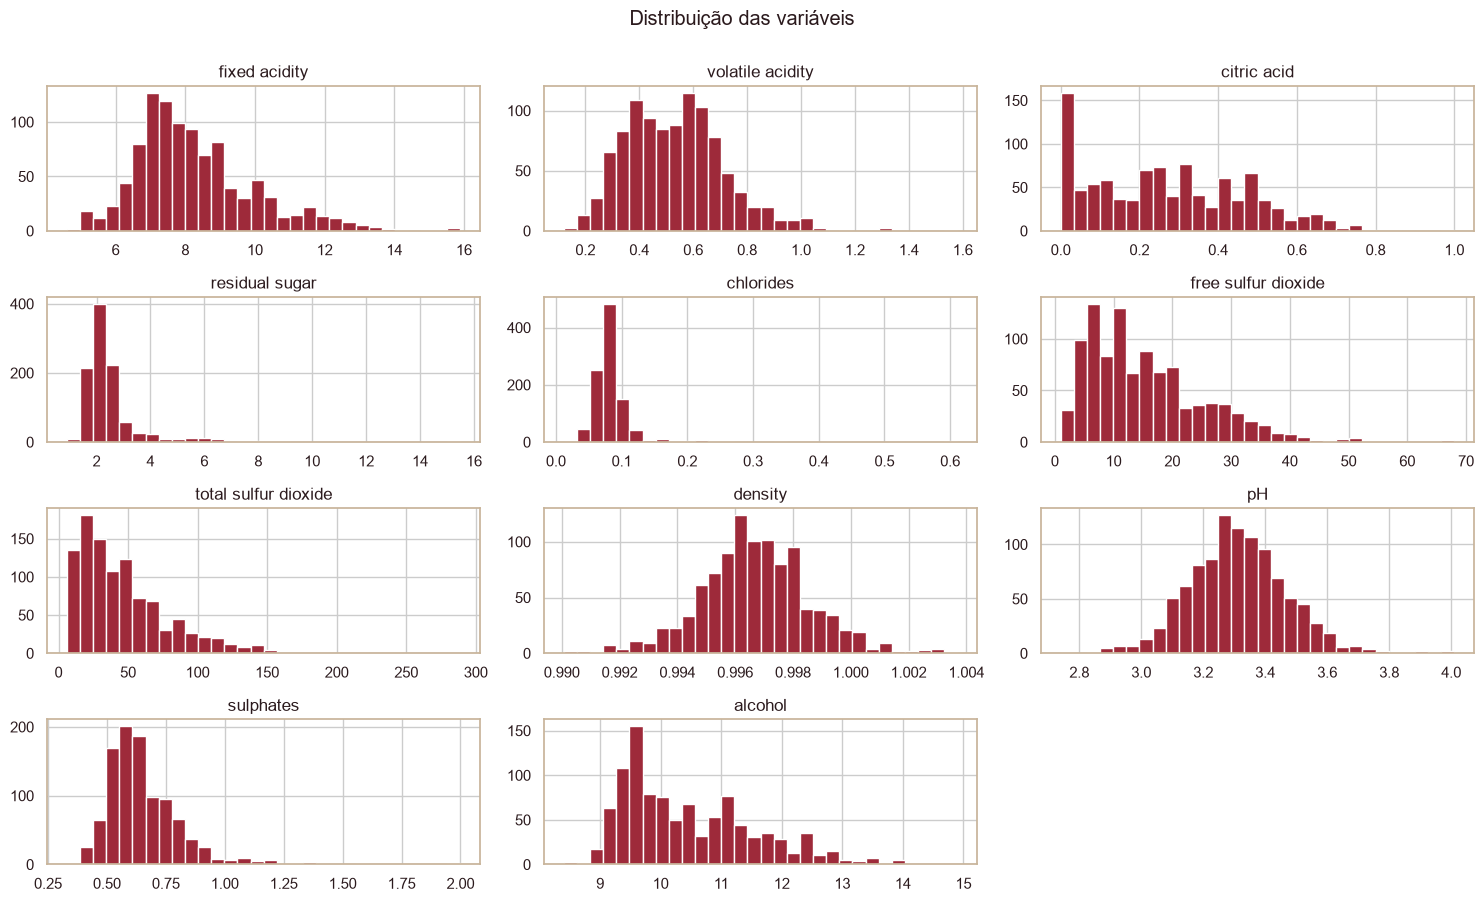

In [11]:
df[FEATURES].hist(bins=30, figsize=(15, 9), color=TINTO,
                  edgecolor="white")
plt.suptitle("Distribuição das variáveis", y=1.0)
plt.tight_layout()

assimetria = df[FEATURES].skew().sort_values(ascending=False)
assimetria.round(2).to_frame("assimetria")

- Densidade e pH têm formato **equilibrado**: a maioria dos vinhos fica no meio e poucos nos extremos.
- Cloretos, açúcar residual e sulfatos se **concentram em valores baixos, com alguns casos muito altos** (maior assimetria na tabela).

**O que isso significa:** esses poucos valores extremos poderiam "puxar" o resultado de alguns modelos. Na Etapa 3 aplicamos um ajuste (logaritmo) que aproxima esses valores dos demais.

### 2.4 O que diferencia um vinho de alta qualidade?

alta_qualidade,0,1
fixed acidity,7.800,8.600
volatile acidity,0.550,0.360
citric acid,0.240,0.400
residual sugar,2.200,2.300
chlorides,0.080,0.071
free sulfur dioxide,14.000,12.000
total sulfur dioxide,41.000,27.000
density,0.997,0.995
pH,3.310,3.270
sulphates,0.600,0.740


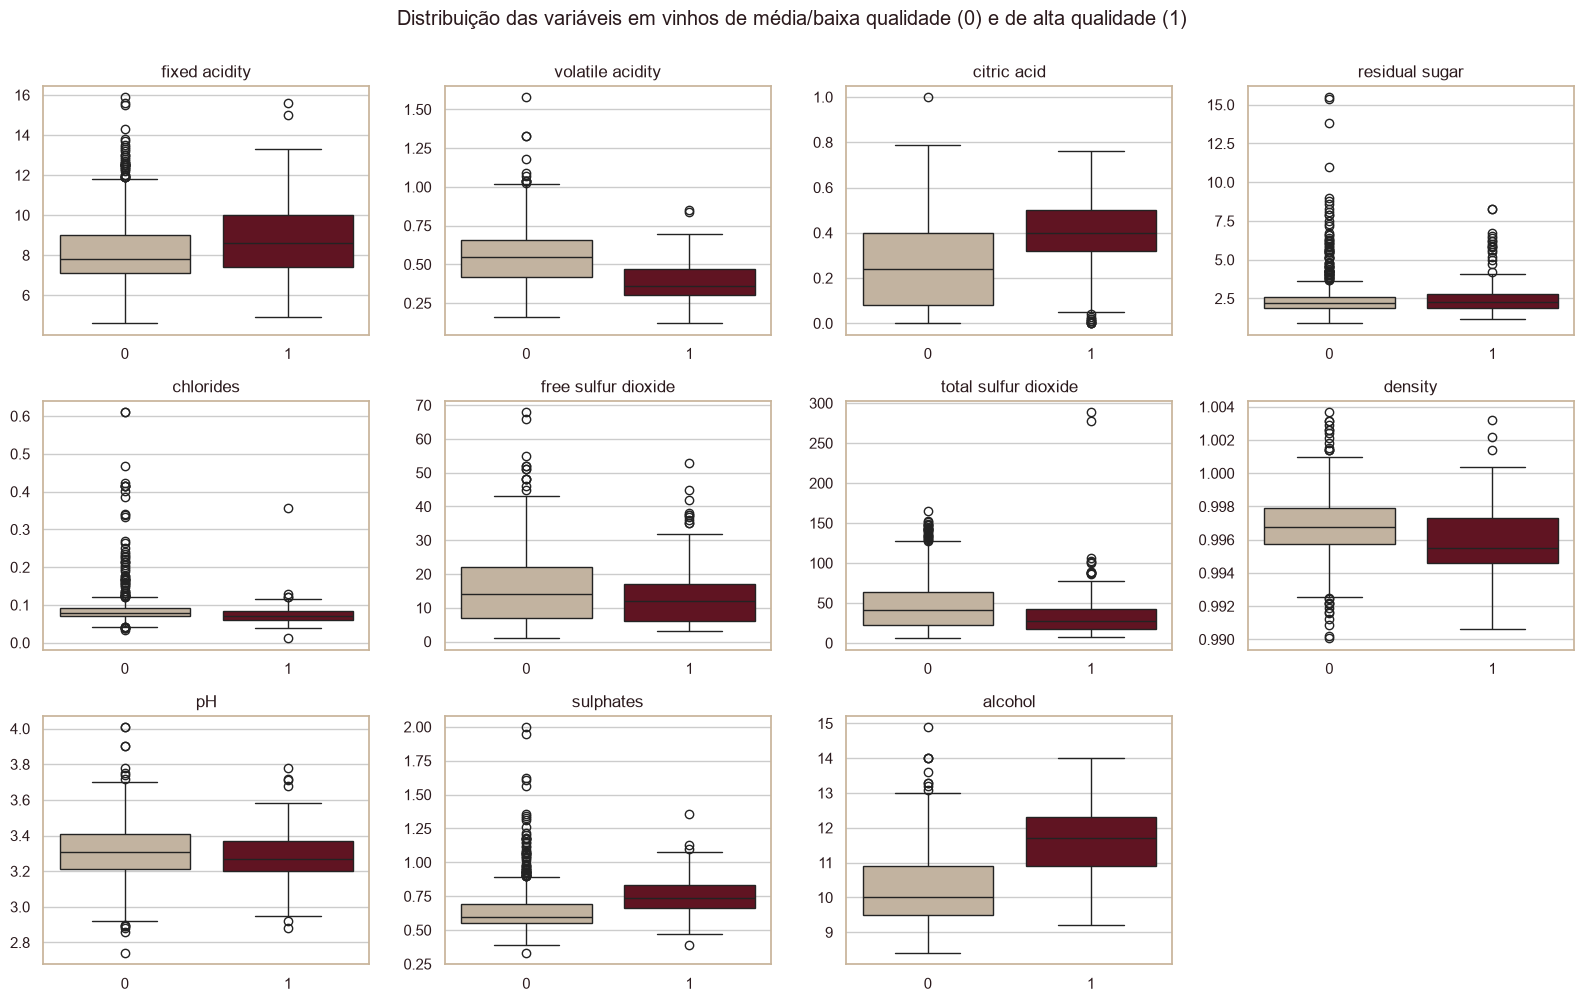

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(x=TARGET, y=col, data=df, palette=CORES, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Distribuição das variáveis em vinhos de média/baixa qualidade (0) e de alta qualidade (1)",
             y=1.0)
plt.tight_layout()

df.groupby(TARGET)[FEATURES].median().T.round(3)

Comparando os valores típicos (mediana) dos dois grupos, os vinhos de alta qualidade têm:
- **mais álcool**: 11,7% contra 10,0%;
- **mais sulfatos**: 0,74 contra 0,60;
- **menos acidez volátil** (o "gosto de vinagre"): 0,36 contra 0,55;
- **mais ácido cítrico** e **menos SO₂ total** (conservante).

**O que isso significa:** já dá para ver um "perfil" do vinho bom. Já o açúcar, o pH e o SO₂ livre são quase iguais nos dois grupos, então devem ajudar pouco a separar os vinhos.

### 2.5 Correlações entre as variáveis

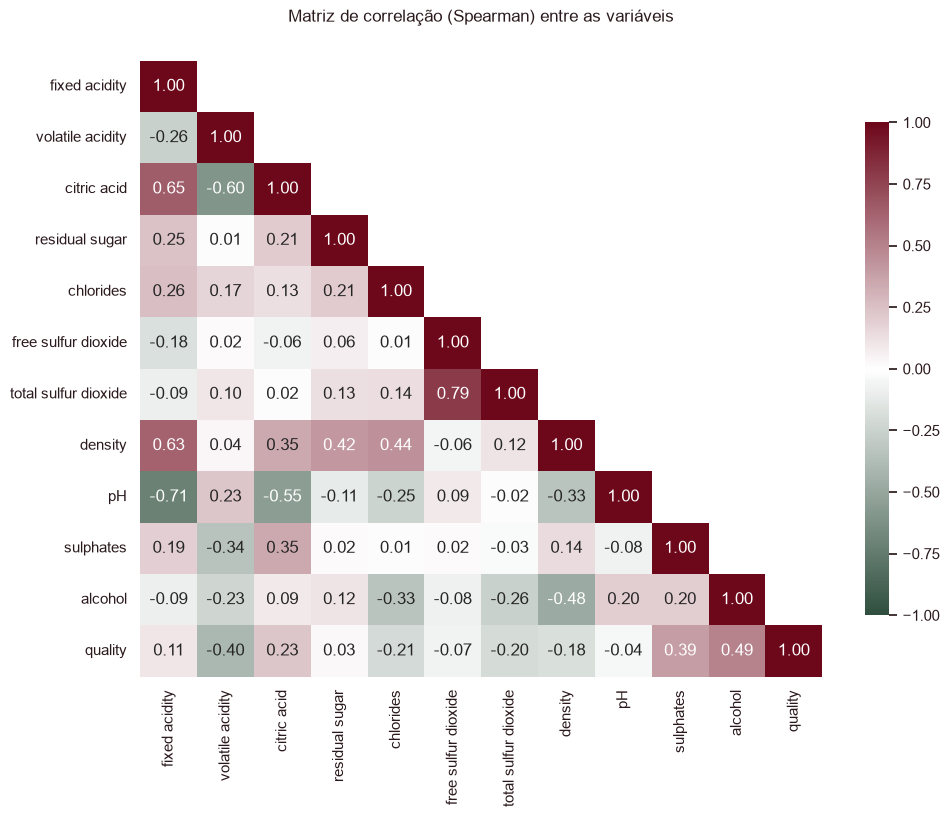

In [13]:
corr = df[FEATURES + ["quality"]].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap=CMAP_DIV,
            center=0, vmin=-1, vmax=1, cbar_kws={"shrink": 0.8})
plt.grid(False)
plt.title("Matriz de correlação (Spearman) entre as variáveis", y=1.05)
plt.show()

A correlação mostra se duas medidas andam juntas: perto de **+1** sobem juntas, perto de **−1** uma sobe quando a outra desce, e perto de **0** não têm relação. Usamos o método de Spearman, que sofre menos com valores extremos (Outliers).

**Relação de cada medida com a qualidade**

| Medida | Correlação | Por que acontece |
|---|---|---|
| Álcool | **+0,49** | Mais álcool dá mais corpo ao vinho e indica uvas bem maduras. |
| Sulfatos | **+0,39** | Protegem o vinho contra bactérias e oxidação, evitando defeitos. |
| Ácido cítrico | +0,23 | Traz frescor e sabor de fruta; também indica uva saudável. |
| Acidez fixa | +0,11 | Dá estrutura ao vinho, mas o efeito é pequeno. |
| Acidez volátil | **−0,40** | É praticamente vinagre; em excesso é um defeito claro. |
| Cloretos | −0,21 | Deixam o vinho salgado e desequilibrado. |
| SO₂ total | −0,20 | Conservante em excesso prejudica o aroma. |
| Densidade | −0,18 | Só reflete o álcool (o álcool é mais leve que a água). |
| pH, açúcar e SO₂ livre | ≈ 0 | Quase não influenciam a nota. |

**Relação entre as próprias medidas**

| Par | Correlação | Por que acontece |
|---|---|---|
| SO₂ livre × SO₂ total | +0,79 | O SO₂ livre é uma parte do total. |
| Acidez fixa × pH | −0,71 | Quanto mais ácido, menor o pH. |
| Acidez fixa × ácido cítrico | +0,65 | O ácido cítrico é um dos ácidos que formam a acidez fixa. |
| Acidez fixa × densidade | +0,63 | Ácidos dissolvidos deixam o líquido mais denso. |
| Acidez volátil × ácido cítrico | −0,60 | As bactérias que produzem vinagre consomem o ácido cítrico. |
| Densidade × álcool | −0,48 | O álcool é mais leve que a água. |

**O que isso significa:** algumas medidas contam quase a mesma história (ex.: SO₂ livre e total). Isso não atrapalha os modelos, mas pede cuidado ao interpretar o peso de cada medida isoladamente.

### 2.6 Outliers e valores inconsistentes

In [14]:
q1 = df[FEATURES].quantile(0.25)
q3 = df[FEATURES].quantile(0.75)
iqr = q3 - q1
fora = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)

print("Valores fora da curva por medida (regra 1,5 x IQR):")
display(fora.sum().sort_values(ascending=False).to_frame("n").T)

Valores fora da curva por medida (regra 1,5 x IQR):


,residual sugar,chlorides,sulphates,fixed acidity,total sulfur dioxide,density,pH,free sulfur dioxide,volatile acidity,alcohol,citric acid
n,95,71,41,37,33,30,24,16,10,6,1


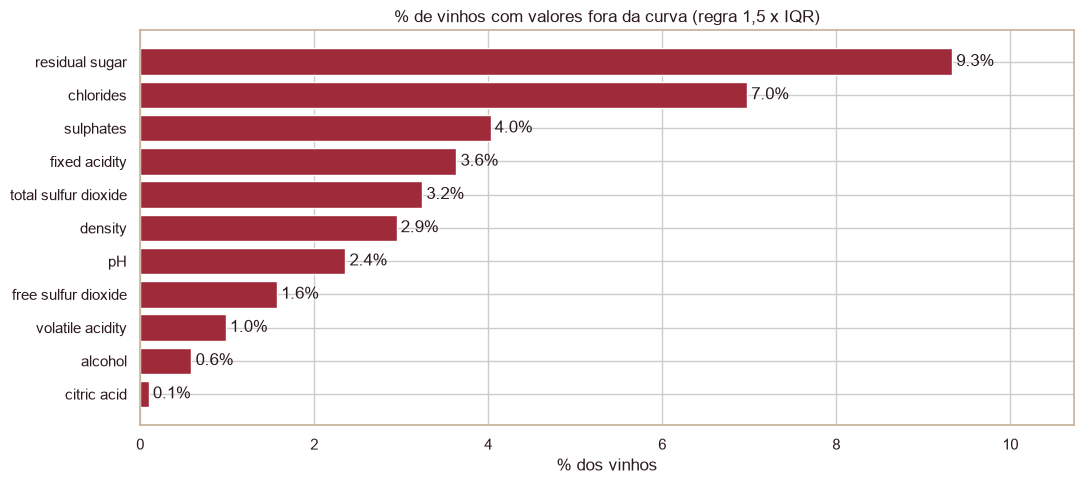

In [15]:
# % de vinhos fora da curva em cada característica química
pct_fora = (fora.mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(pct_fora.index, pct_fora.values, color=TINTO)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="% de vinhos com valores fora da curva (regra 1,5 x IQR)",
       xlabel="% dos vinhos", xlim=(0, pct_fora.max() * 1.15))
plt.tight_layout()

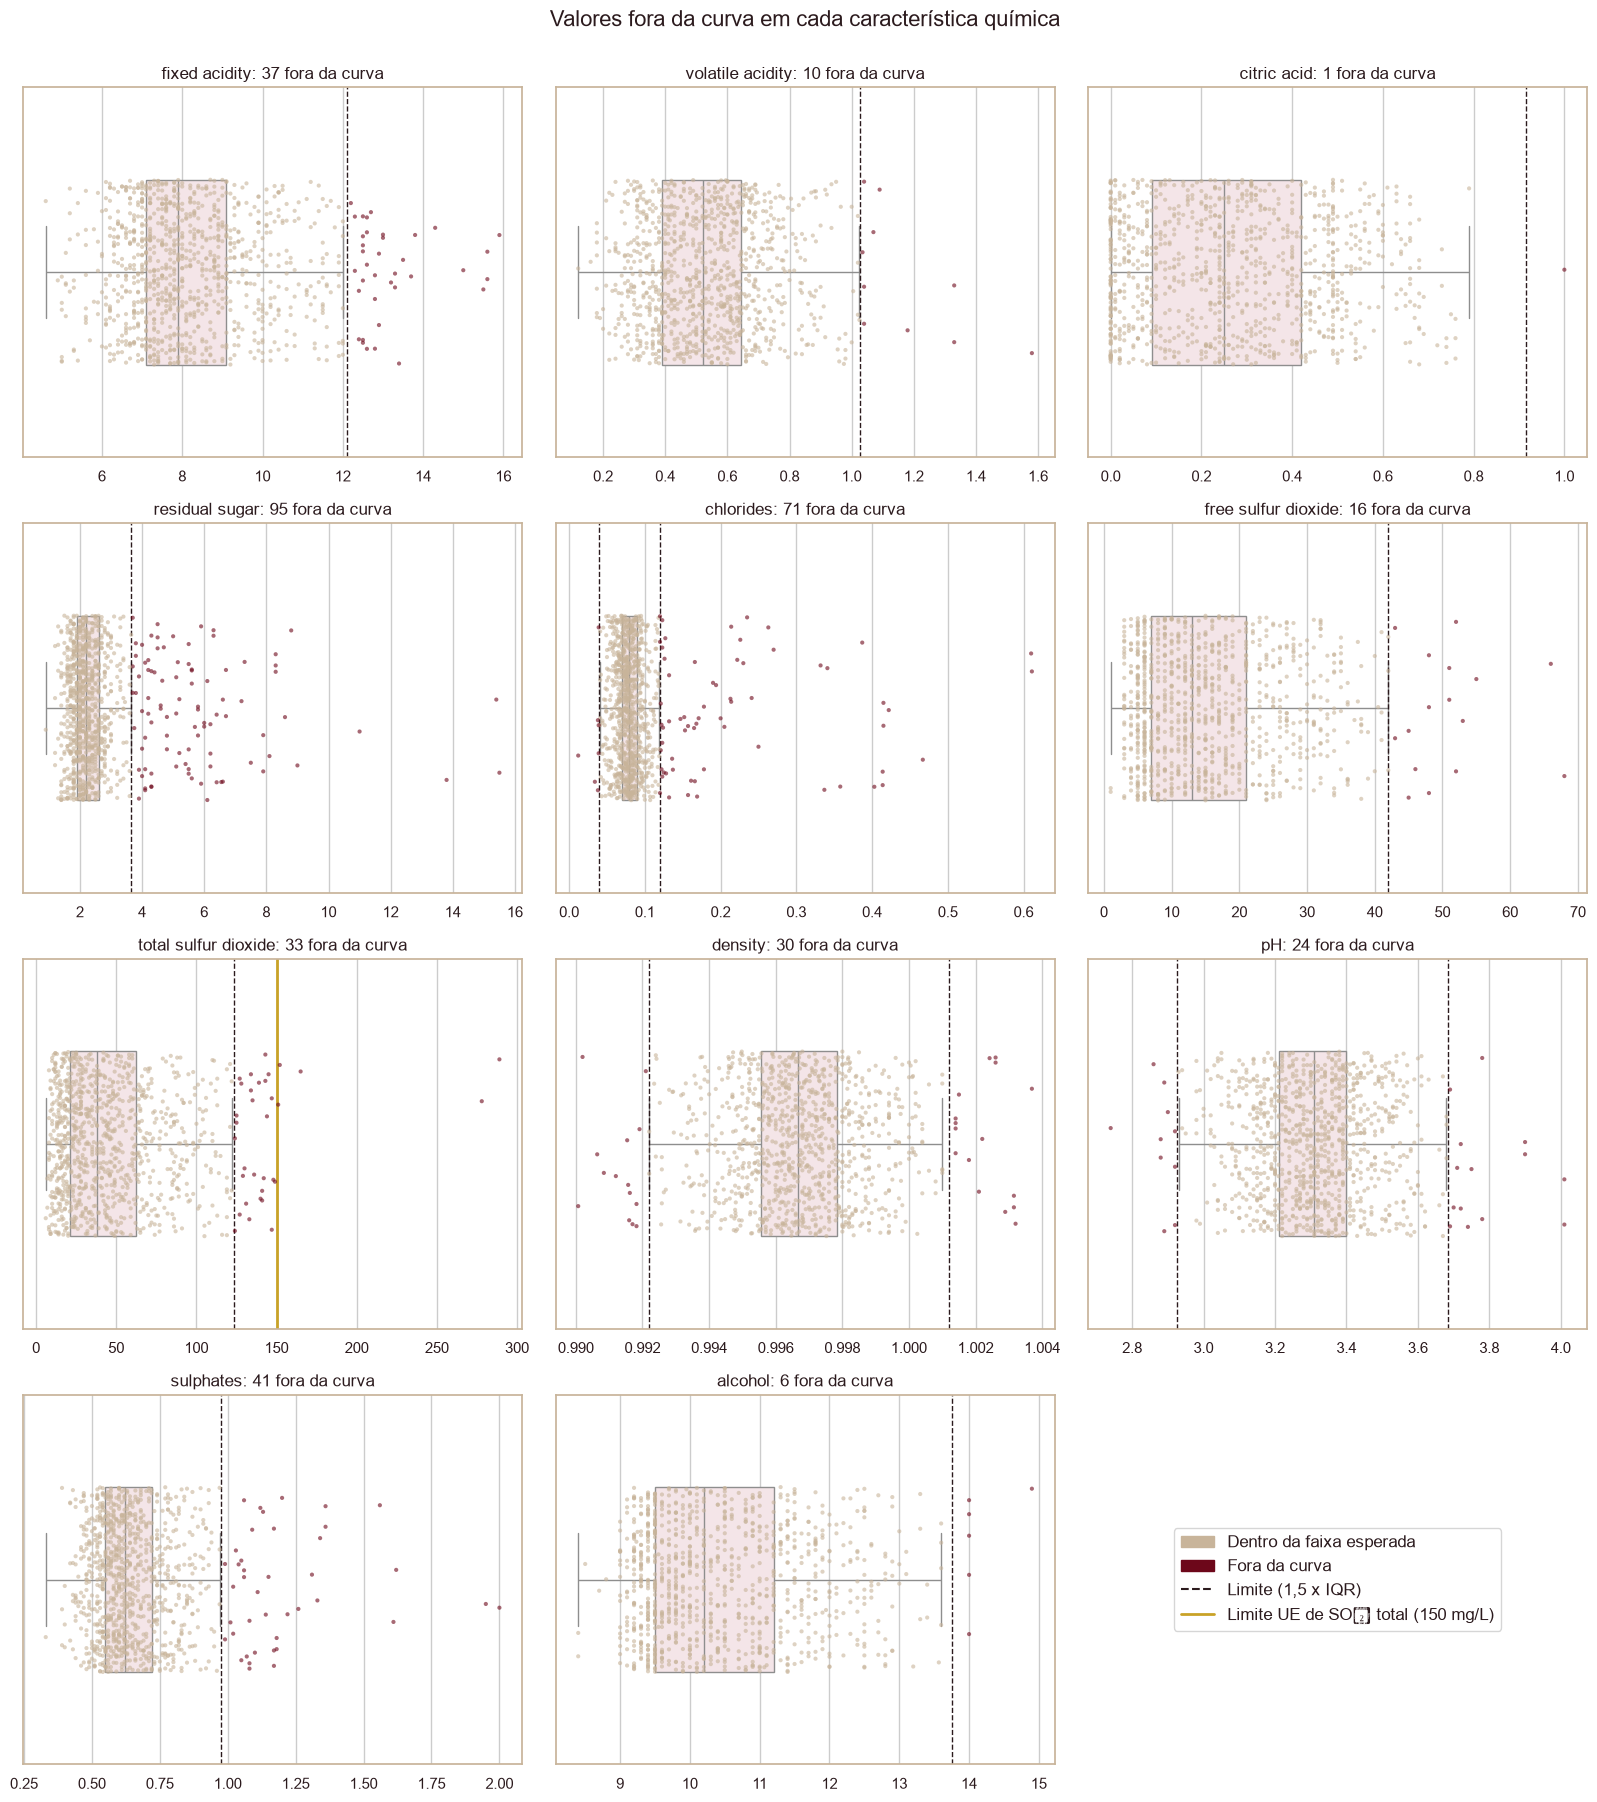

In [16]:
# Onde estão os valores fora da curva em cada característica química
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
CORES_FORA = {False: CORTICA, True: BORDO}

fig, axes = plt.subplots(4, 3, figsize=(16, 18))
for ax, col in zip(axes.flat, fora.columns):
    sns.boxplot(x=df[col], ax=ax, color=ROSE_CLARO, showfliers=False,
                width=0.5)
    sns.stripplot(x=df[col], hue=fora[col], palette=CORES_FORA, ax=ax,
                  size=3, alpha=0.6, jitter=0.25, legend=False)
    for limite in (limite_inf[col], limite_sup[col]):
        if df[col].min() <= limite <= df[col].max():
            ax.axvline(limite, color=TEXTO, ls="--", lw=1)
    if col == "total sulfur dioxide":
        ax.axvline(150, color=DOURADO, lw=2)
    ax.set(title=f"{col}: {fora[col].sum()} fora da curva", xlabel="")

legenda = [
    Patch(color=CORTICA, label="Dentro da faixa esperada"),
    Patch(color=BORDO, label="Fora da curva"),
    plt.Line2D([], [], color=TEXTO, ls="--", label="Limite (1,5 x IQR)"),
    plt.Line2D([], [], color=DOURADO, lw=2,
               label="Limite UE de SO₂ total (150 mg/L)"),
]
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=legenda, loc="center", fontsize=12)
fig.suptitle("Valores fora da curva em cada característica química",
             y=1.0, fontsize=16)
plt.tight_layout()

**O que isso significa**: açúcar residual (9,3% dos vinhos) e cloretos (7,0%) concentram a maior parte dos valores fora da curva, quase sempre acima do esperado: vinhos mais doces ou mais salgados, que existem na prática. Os pontos ficam espalhados de forma contínua, sem um “salto” que indique erro. A exceção são os 2 vinhos com SO₂ total muito acima de todos os outros.

In [17]:
# Checagens de consistência química
so2_livre = df["free sulfur dioxide"]
so2_total = df["total sulfur dioxide"]

print("SO2 livre > SO2 total:", (so2_livre > so2_total).sum())
print("Valores negativos:", (df[FEATURES] < 0).sum().sum())
print("Faixa de pH:", df["pH"].min(), "a", df["pH"].max())
print("SO2 total > 150 mg/L (limite UE para tintos secos):")
df.loc[so2_total > 150, ["free sulfur dioxide", "total sulfur dioxide",
                         "quality"]]

SO2 livre > SO2 total: 0
Valores negativos: 0
Faixa de pH: 2.74 a 4.01
SO2 total > 150 mg/L (limite UE para tintos secos):


,free sulfur dioxide,total sulfur dioxide,quality
225,40.5,165.0,6
330,34.0,151.0,5
434,35.0,152.0,5
680,37.5,278.0,7
681,37.5,289.0,7


**O que isso significa**
- Pela regra estatística usual, várias medidas têm valores "fora da curva" (ex.: 95 vinhos com açúcar alto). Mas são valores **possíveis na prática** (vinhos mais doces ou mais salgados), e não erros. Por isso foram mantidos.
- **Não há dados impossíveis:** nenhum valor negativo, o SO₂ livre nunca é maior que o total e o pH está na faixa normal de vinhos.
- **Atenção:** 2 vinhos têm SO₂ total de 278 e 289 mg/L, quase o dobro do limite europeu (150 mg/L) e muito acima de todos os outros. **Pode ser erro de digitação.** Como são só 2 casos, foram mantidos, e o ajuste da Etapa 3 reduz o peso deles.

# Etapa 3 – Pré-processamento de dados

### 3.1 Dados faltantes e duplicatas
A base não tem dados faltando, então **nenhum tratamento foi necessário**. O único ajuste foi a remoção dos vinhos repetidos, feita na Etapa 2. O gráfico mostra o efeito dessa limpeza em cada classe.

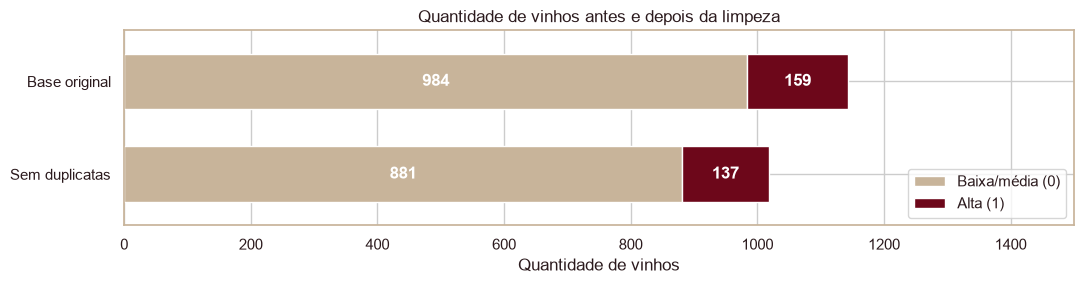

In [18]:
bruto = pd.read_csv("../data/WineQT.csv").drop(columns="Id")
bruto[TARGET] = (bruto["quality"] >= 7).astype(int)
bases = pd.DataFrame({
    "Base original": bruto[TARGET].value_counts(),
    "Sem duplicatas": df[TARGET].value_counts(),
}).T[[0, 1]]

fig, ax = plt.subplots(figsize=(11, 3))
bases.plot.barh(stacked=True, color=CORES, ax=ax, width=0.6)
for barras in ax.containers:
    ax.bar_label(barras, label_type="center", color="white",
                 fontweight="bold")
ax.invert_yaxis()
ax.set(title="Quantidade de vinhos antes e depois da limpeza",
       xlabel="Quantidade de vinhos", xlim=(0, 1500))
ax.legend(["Baixa/média (0)", "Alta (1)"], loc="lower right")
plt.tight_layout()

**O que isso significa:** saíram 103 vinhos de média/baixa qualidade e 22 de alta qualidade. A proporção de vinhos bons quase não mudou (13,9% → 13,5%), então a limpeza **não distorceu o problema**, apenas evitou contar o mesmo vinho duas vezes.

### 3.2 Feature engineering
Foram criadas 3 novas medidas combinando as existentes, para facilitar o trabalho dos modelos.

In [19]:
# Proporção do conservante que está ativa
df["so2_livre_pct"] = df["free sulfur dioxide"] / df["total sulfur dioxide"]
# Junta os dois fatores positivos mais fortes
df["alcool_x_sulfatos"] = df["alcohol"] * df["sulphates"]
# Muito álcool e pouca acidez volátil
df["alcool_por_volatil"] = df["alcohol"] / df["volatile acidity"]

NOVAS = ["so2_livre_pct", "alcool_x_sulfatos", "alcool_por_volatil"]
FEATURES = FEATURES + NOVAS

corr_novas = df[NOVAS + ["quality"]].corr(method="spearman")["quality"]
corr_novas.drop("quality").round(2).to_frame("correlação com a nota")

,correlação com a nota
so2_livre_pct,0.22
alcool_x_sulfatos,0.51
alcool_por_volatil,0.49


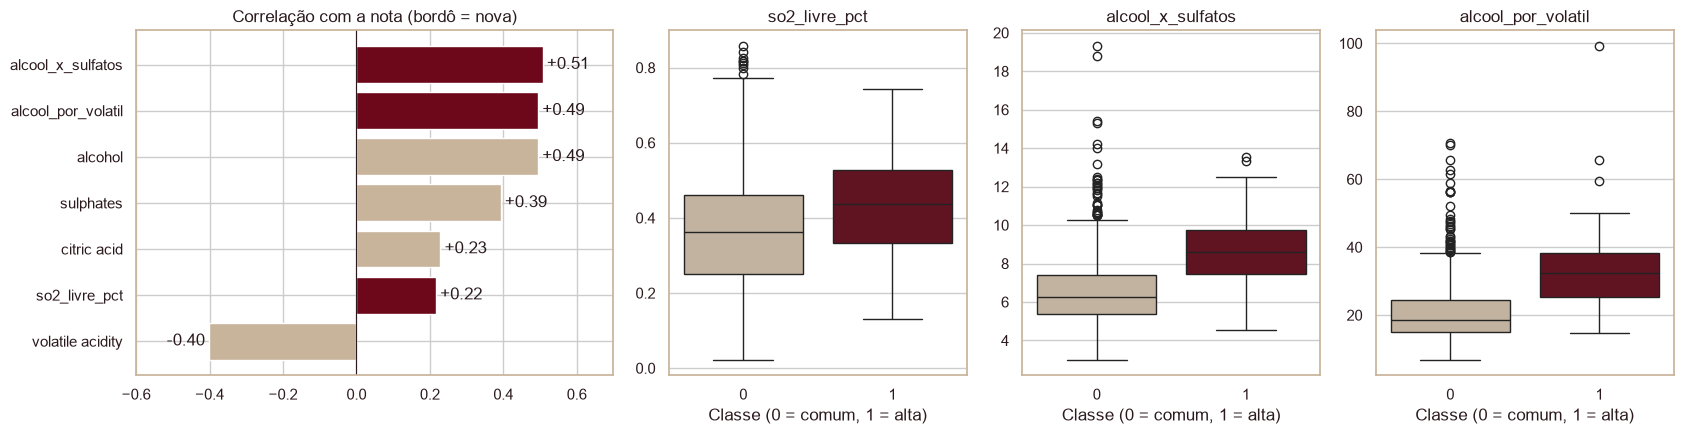

In [20]:
# Novas medidas x originais mais fortes: relação com a nota
destaque = ["alcohol", "sulphates", "volatile acidity", "citric acid"]
corr_q = df[destaque + NOVAS + ["quality"]].corr(method="spearman")
corr_q = corr_q["quality"].drop("quality").sort_values()

fig, ax = plt.subplots(1, 4, figsize=(17, 4.5),
                       gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
cores_barras = [BORDO if c in NOVAS else CORTICA for c in corr_q.index]
ax[0].barh(corr_q.index, corr_q.values, color=cores_barras)
ax[0].bar_label(ax[0].containers[0], fmt="%+.2f", padding=3)
ax[0].axvline(0, color=TEXTO, lw=0.8)
ax[0].set(title="Correlação com a nota (bordô = nova)", xlim=(-0.6, 0.7))
for eixo, col in zip(ax[1:], NOVAS):
    sns.boxplot(x=TARGET, y=col, data=df, palette=CORES, ax=eixo)
    eixo.set(title=col, xlabel="Classe (0 = comum, 1 = alta)", ylabel="")
plt.tight_layout()

**O que isso significa**
- **Álcool × sulfatos** é a medida **mais ligada à qualidade** (0,51), mais até que o álcool sozinho (0,49).
- **Álcool ÷ acidez volátil** resume o "vinho bom" em um único número: muito álcool e pouco vinagre. Nos boxplots, as caixas dos vinhos de alta qualidade ficam claramente acima.
- **% de SO₂ livre** mostra que a **proporção** de conservante ativo importa mais do que a quantidade total.

### 3.3 Divisão treino/teste
Antes de treinar qualquer modelo, separamos uma parte dos vinhos que **só será usada no final**, como uma prova:
- **Treino (80%):** os modelos aprendem com esses vinhos;
- **Teste (20%):** vinhos guardados que nenhum modelo vê durante o desenvolvimento.

A divisão é **estratificada**: e mantém a mesma proporção de vinhos de alta qualidade nos dois grupos. A semente fixa (`SEED = 42`) garante que a divisão seja sempre a mesma.

In [21]:
X = df[FEATURES]
y = df[TARGET]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Treino: {X_treino.shape} | % alta: {y_treino.mean():.1%}")
print(f"Teste:  {X_teste.shape} | % alta: {y_teste.mean():.1%}")

Treino: (814, 14) | % alta: 13.5%
Teste:  (204, 14) | % alta: 13.2%


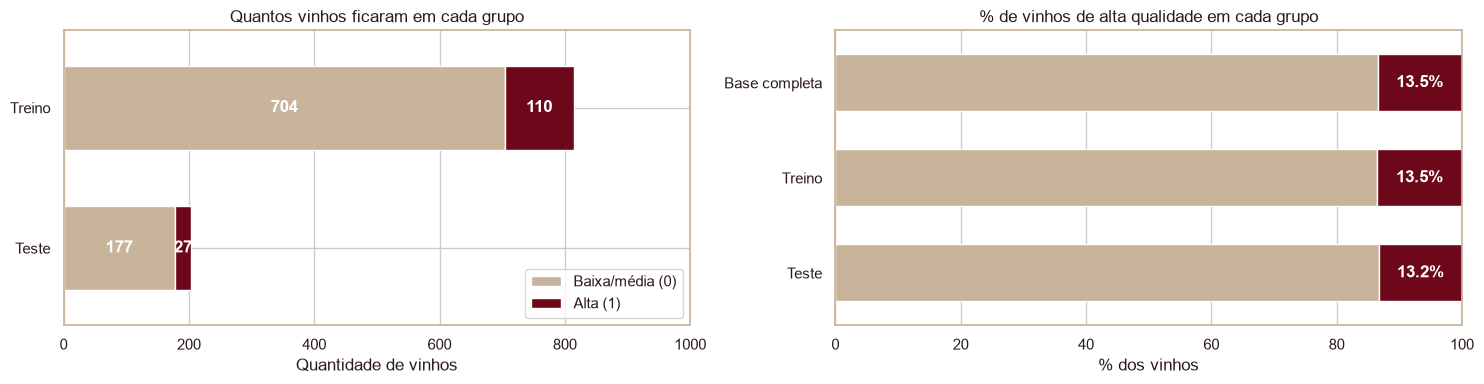

In [22]:
grupos = {"Base completa": y, "Treino": y_treino, "Teste": y_teste}
contagem = pd.DataFrame({k: v.value_counts() for k, v in grupos.items()})
contagem = contagem.T[[0, 1]]
proporcao = contagem.div(contagem.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
treino_teste = contagem.loc[["Treino", "Teste"]]
treino_teste.plot.barh(stacked=True, color=CORES, ax=ax[0], width=0.6)
for barras in ax[0].containers:
    ax[0].bar_label(barras, label_type="center", color="white",
                    fontweight="bold")
ax[0].invert_yaxis()
ax[0].set(title="Quantos vinhos ficaram em cada grupo",
          xlabel="Quantidade de vinhos", xlim=(0, 1000))
ax[0].legend(["Baixa/média (0)", "Alta (1)"], loc="lower right")

proporcao.plot.barh(stacked=True, color=CORES, ax=ax[1], width=0.6,
                    legend=False)
ax[1].bar_label(ax[1].containers[1], fmt="%.1f%%", label_type="center",
                color="white", fontweight="bold")
ax[1].invert_yaxis()
ax[1].set(title="% de vinhos de alta qualidade em cada grupo",
          xlabel="% dos vinhos", xlim=(0, 100))
plt.tight_layout()

**O que isso significa:** o treino ficou com 814 vinhos (110 de alta qualidade) e o teste com 204 (27 de alta qualidade). Com a  estratificação, a proporção de vinhos considerados de alta qualidade é praticamente a mesma nos três grupos (**13,5%, 13,5% e 13,2%**). Sem isso, o sorteio poderia deixar o teste com poucos vinhos bons e a avaliação ficaria comprometida.

O teste também precisa ser um **retrato fiel da base**. Os gráficos abaixo comparam as notas e as principais medidas nos dois grupos.

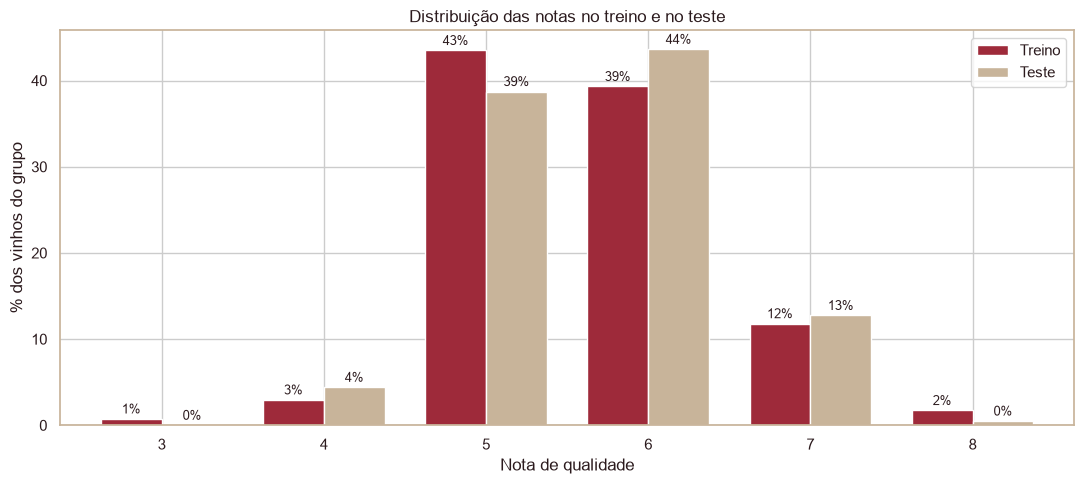

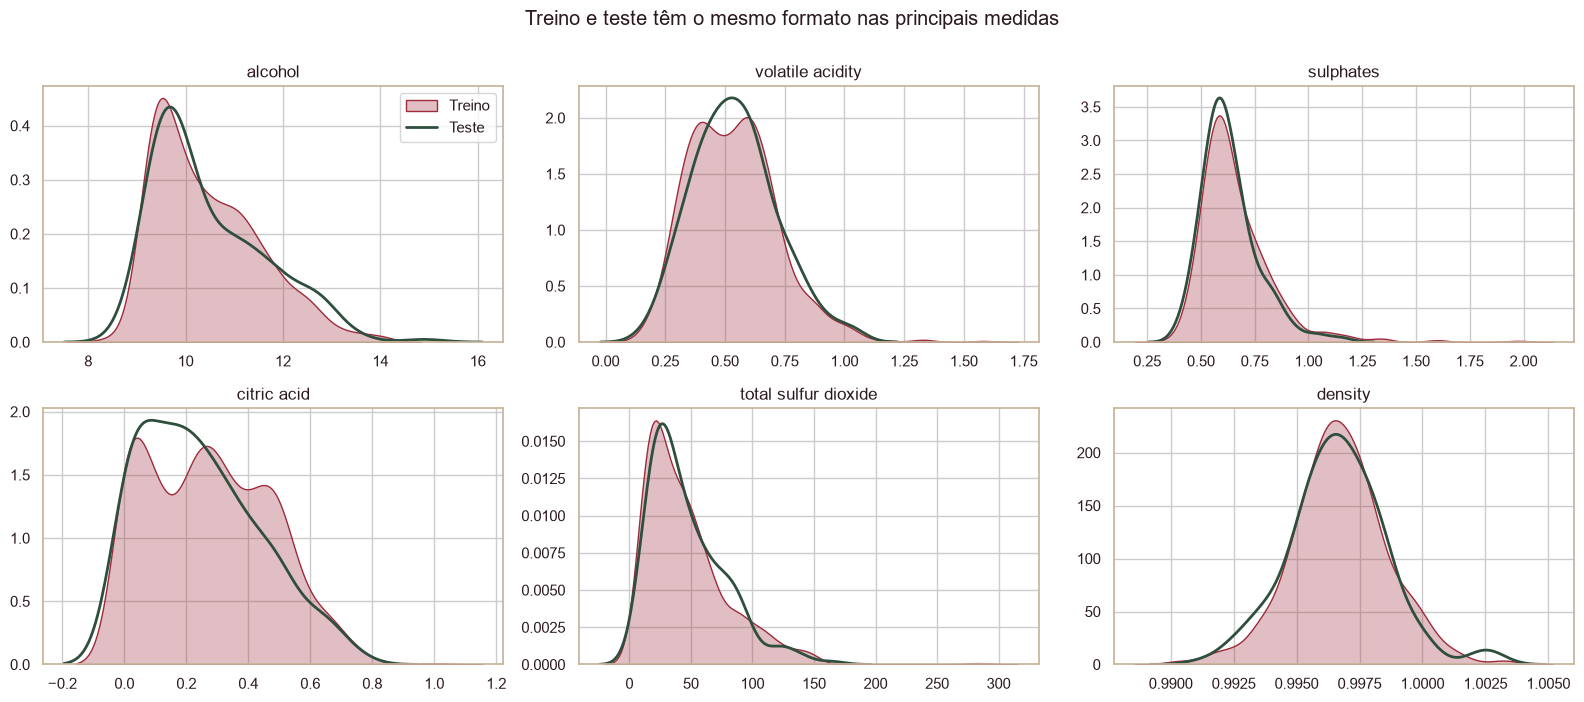

In [23]:
nota = df["quality"]
notas = pd.DataFrame({
    "Treino": nota.loc[X_treino.index].value_counts(normalize=True),
    "Teste": nota.loc[X_teste.index].value_counts(normalize=True),
}).sort_index() * 100

fig, ax = plt.subplots(figsize=(11, 5))
notas.plot.bar(color=[TINTO, CORTICA], ax=ax, rot=0, width=0.75)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=9)
ax.set(title="Distribuição das notas no treino e no teste",
       xlabel="Nota de qualidade", ylabel="% dos vinhos do grupo")
plt.tight_layout()
plt.show()

PRINCIPAIS = ["alcohol", "volatile acidity", "sulphates", "citric acid",
              "total sulfur dioxide", "density"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for eixo, col in zip(axes.flat, PRINCIPAIS):
    sns.kdeplot(X_treino[col], ax=eixo, color=TINTO, fill=True, alpha=0.3,
                label="Treino")
    sns.kdeplot(X_teste[col], ax=eixo, color=VERDE_GARRAFA, lw=2,
                label="Teste")
    eixo.set(title=col, xlabel="", ylabel="")
axes.flat[0].legend()
fig.suptitle("Treino e teste têm o mesmo formato nas principais medidas",
             y=1.0)
plt.tight_layout()

**O que isso significa:** as notas aparecem em proporções parecidas nos dois grupos e as curvas de treino e teste praticamente se sobrepõem em todas as medidas. O teste é uma **miniatura da base inteira**, então o resultado dele vale como uma boa previsão do uso real.

### 3.4 Padronização
Os modelos recebem as medidas em escalas muito diferentes. Aplicamos dois ajustes, **aprendidos só com o treino** para não "espiar" o teste:
1. **Logaritmo** nas medidas assimétricas, para aproximar os valores extremos dos demais;
2. **Padronização**, que coloca todas as medidas na mesma escala (média 0, desvio 1).

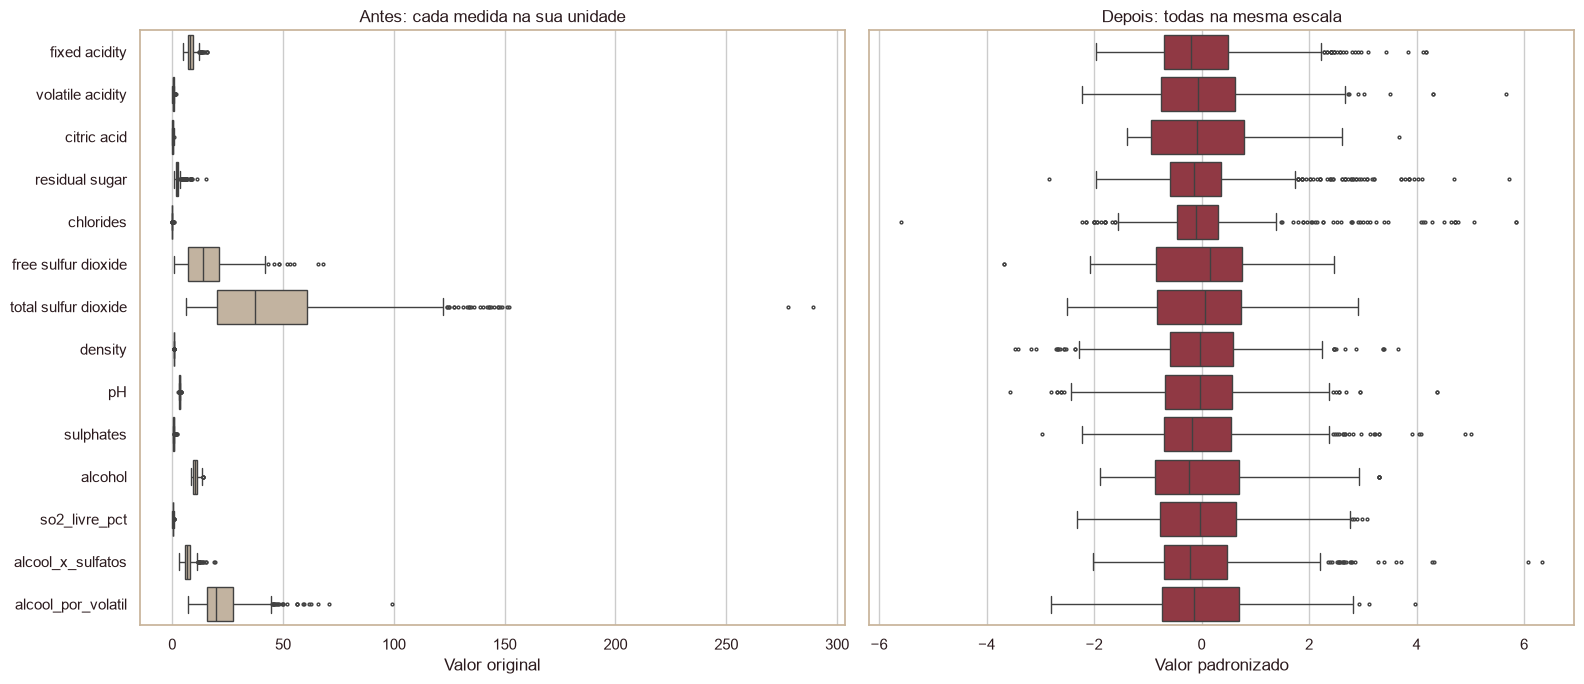

In [24]:
# Log nas variáveis assimétricas + padronização (média 0, desvio 1)
ASSIMETRICAS = [
    "residual sugar", "chlorides", "sulphates", "free sulfur dioxide",
    "total sulfur dioxide", "alcool_por_volatil",
]
log = FunctionTransformer(np.log, feature_names_out="one-to-one")
preproc = make_pipeline(
    ColumnTransformer(
        [("log", log, ASSIMETRICAS)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    ),
    StandardScaler(),
)

X_prep = pd.DataFrame(
    preproc.fit_transform(X_treino),
    columns=preproc[0].get_feature_names_out(),
)[FEATURES]

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
sns.boxplot(data=X_treino, orient="h", color=CORTICA, ax=ax[0],
            fliersize=2)
ax[0].set(title="Antes: cada medida na sua unidade",
          xlabel="Valor original")
sns.boxplot(data=X_prep, orient="h", color=TINTO, ax=ax[1], fliersize=2)
ax[1].set(title="Depois: todas na mesma escala", xlabel="Valor padronizado")
ax[1].set_yticklabels([])
plt.tight_layout()

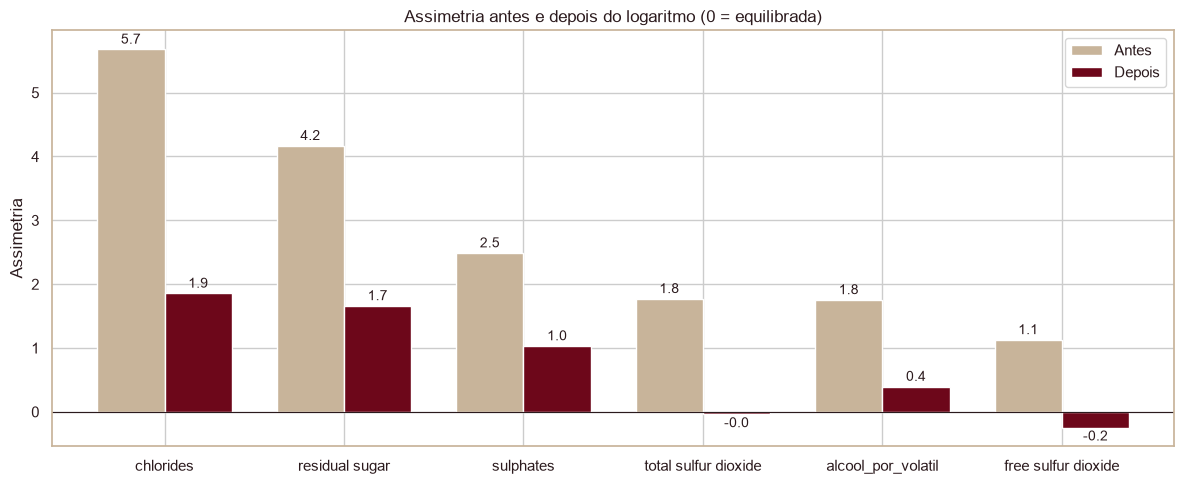

In [25]:
assim = pd.DataFrame({
    "Antes": X_treino[ASSIMETRICAS].skew(),
    "Depois": X_prep[ASSIMETRICAS].skew(),
}).sort_values("Antes", ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
assim.plot.bar(color=[CORTICA, BORDO], ax=ax, rot=0, width=0.75)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", padding=2, fontsize=10)
ax.axhline(0, color=TEXTO, lw=0.8)
ax.set(title="Assimetria antes e depois do logaritmo (0 = equilibrada)",
       ylabel="Assimetria")
plt.tight_layout()

**O que isso significa**
- **Antes**, o SO₂ total (até 289) achata todas as outras medidas perto de zero: um modelo sensível à escala daria peso demais a ele só por causa da unidade.
- **Depois**, todas as medidas ocupam a mesma faixa e podem ser comparadas de igual para igual.
- O logaritmo reduziu a assimetria (ex.: cloretos de 5,7 para 1,9 e açúcar de 4,2 para 1,7 no treino).
- O ajuste é usado na Regressão Logística e no SVM. A Random Forest decide por cortes e não precisa dele.

# Etapa 4 – Desenvolvimento de modelos

Foram testados 3 modelos:
- **Regressão Logística:** dá um peso para cada medida e soma tudo.
- **SVM:** procura a melhor "linha divisória" entre vinhos de alta qualidade e média/baixa qualidade, mesmo quando essa linha é curva.
- **Random Forest:** reúne centenas de árvores de decisão (sequências de perguntas como "o álcool é maior que 11%?") e decide por votação.

Também incluímos uma **referência** que sempre responde "vinho de média/baixa qualidade", para ter uma base de comparação.

**Como ler as métricas**

| Métrica | Pergunta que responde |
|---|---|
| Acurácia | De todos os vinhos, quantos o modelo classificou certo? |
| Precisão | Quando o modelo diz "este é bom", quantas vezes acerta? |
| Recall | De todos os vinhos de alta qualidade, quantos o modelo encontrou? |
| F1 | Equilíbrio entre precisão e recall |
| ROC-AUC | Nota geral de 0,5 (chute) a 1 (perfeito) para separar de média/baixa qualidade e alta qualidade, resumida pela curva ROC |

**Atenção à acurácia:** como só 13,5% dos vinhos são de alta qualidade, um modelo que chama todo vinho de comum (média/baixa qualidade) já acerta 86,5%. Por isso a acurácia aparece nas tabelas, mas a escolha dos modelos se apoia na **ROC-AUC** (separar bons de comuns) e no **F1** (encontrar os bons sem muitos falsos positivos).

**Como comparamos sem tocar no teste:** usamos **validação cruzada**. O treino é dividido em 5 partes; em cada rodada, o modelo aprende com 4 partes e é avaliado na quinta. Ao final, cada vinho do treino serviu de avaliação uma vez, e o teste continua guardado.

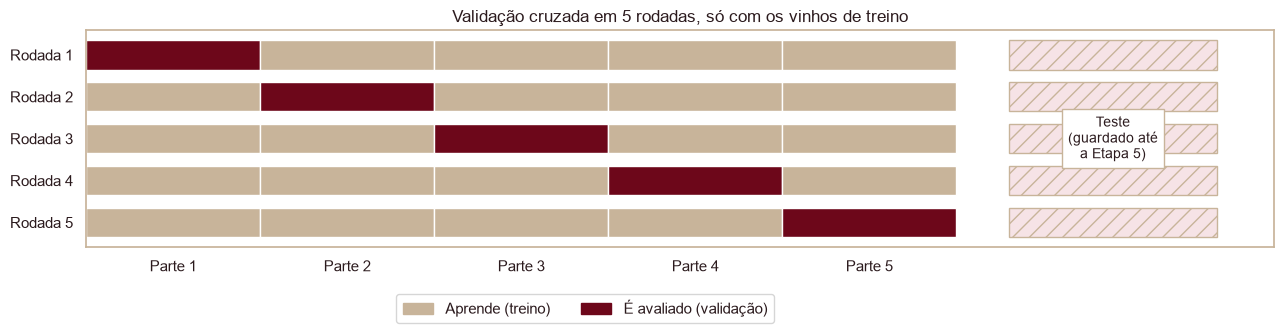

In [26]:
fig, ax = plt.subplots(figsize=(13, 3.6))
for rodada in range(5):
    for parte in range(5):
        cor = BORDO if parte == rodada else CORTICA
        ax.barh(rodada, 1, left=parte, color=cor, edgecolor="white",
                height=0.7)
    ax.barh(rodada, 1.2, left=5.3, color=ROSE_CLARO, edgecolor=CORTICA,
            hatch="//", height=0.7)
ax.text(5.9, 2, "Teste\n(guardado até\na Etapa 5)", ha="center",
        va="center", fontsize=10, color=TEXTO,
        bbox={"facecolor": "white", "edgecolor": CORTICA})
ax.set_yticks(range(5), [f"Rodada {i}" for i in range(1, 6)])
ax.set_xticks([0.5, 1.5, 2.5, 3.5, 4.5],
              [f"Parte {i}" for i in range(1, 6)])
ax.invert_yaxis()
ax.grid(False)
ax.legend(handles=[Patch(color=CORTICA, label="Aprende (treino)"),
                   Patch(color=BORDO, label="É avaliado (validação)")],
          loc="upper center", bbox_to_anchor=(0.42, -0.18), ncol=2)
ax.set_title("Validação cruzada em 5 rodadas, só com os vinhos de treino")
plt.tight_layout()

### 4.1 Comparação inicial

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {
    "Acurácia": "accuracy",
    "Precisão": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc",
}

modelos = {
    "Referência": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": make_pipeline(
        preproc,
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "SVM": make_pipeline(
        preproc,
        SVC(kernel="rbf", class_weight="balanced", probability=True,
            random_state=SEED),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED,
        n_jobs=-1,
    ),
}


def avaliar_cv(modelos, X, y):
    """Médias por modelo e ROC-AUC de cada rodada da validação cruzada."""
    tabela, rodadas = {}, []
    for nome, modelo in modelos.items():
        res = cross_validate(modelo, X, y, cv=cv, scoring=METRICAS)
        tabela[nome] = {k: res[f"test_{k}"].mean() for k in METRICAS}
        for i, nota in enumerate(res["test_ROC-AUC"], start=1):
            rodadas.append({"Modelo": nome, "Rodada": i, "ROC-AUC": nota})
    return pd.DataFrame(tabela).T.round(3), pd.DataFrame(rodadas)


media_cv, rodadas_cv = avaliar_cv(modelos, X_treino, y_treino)
media_cv

,Acurácia,Precisão,Recall,F1,ROC-AUC
Referência,0.865,0.000,0.000,0.000,0.500
Regressão Logística,0.797,0.384,0.827,0.524,0.887
SVM,0.817,0.402,0.727,0.516,0.871
Random Forest,0.862,0.483,0.573,0.521,0.879


,min,max
Modelo,,
Random Forest,0.84,0.94
Referência,0.50,0.50
Regressão Logística,0.86,0.94
SVM,0.84,0.94


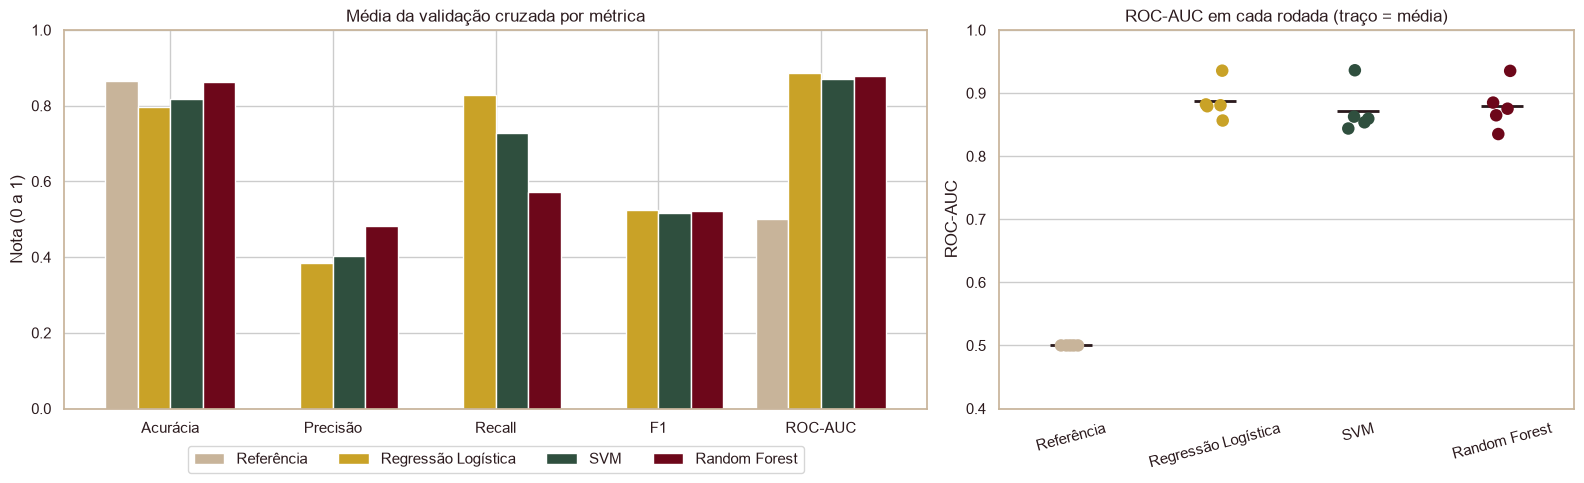

In [28]:
CORES_CV = {"Referência": CORTICA, **CORES_MODELOS}
fig, ax = plt.subplots(1, 2, figsize=(16, 5),
                       gridspec_kw={"width_ratios": [1.5, 1]})
media_cv.T.plot.bar(color=[CORES_CV[m] for m in media_cv.index], ax=ax[0],
                    rot=0, width=0.8)
ax[0].set(title="Média da validação cruzada por métrica", ylim=(0, 1),
          ylabel="Nota (0 a 1)")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)

sns.stripplot(data=rodadas_cv, x="Modelo", y="ROC-AUC", hue="Modelo",
              palette=CORES_CV, size=9, jitter=0.08, legend=False,
              ax=ax[1])
sns.pointplot(data=rodadas_cv, x="Modelo", y="ROC-AUC", color=TEXTO,
              linestyle="none", marker="_", markersize=30, errorbar=None,
              ax=ax[1])
ax[1].set(title="ROC-AUC em cada rodada (traço = média)", xlabel="",
          ylim=(0.4, 1))
ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout()

rodadas_cv.groupby("Modelo")["ROC-AUC"].agg(["min", "max"]).round(2)

**O que isso significa**
- Todos os modelos são muito melhores que a referência, que não encontra nenhum vinho de alta qualidade. Repare na **armadilha da acurácia**: a referência tem a maior acurácia (86,5%) justamente por chamar todo vinho de média/baixa qualidade.
- Os três têm notas gerais parecidas (ROC-AUC entre 0,87 e 0,89), mas **estilos diferentes**:
  - a Regressão Logística encontra mais vinhos de alta qualidade (83%), mas erra mais quando aponta um (só 38% de acerto);
  - a Random Forest é mais cautelosa e acerta mais quando aponta (48%);
  - o SVM fica no meio-termo.
- O gráfico da direita mostra que a nota **varia de uma rodada para outra** (a ROC-AUC de cada modelo vai de cerca de 0,84 a 0,94 conforme a rodada). Por isso decidimos pela média das 5 rodadas, e não por uma única divisão.

**As novas medidas ajudaram?**

Na Etapa 3.2 foram criadas 3 medidas novas, combinando características que já existiam na base:

| Nova medida | Como é calculada | O que representa |
|---|---|---|
| `so2_livre_pct` | SO₂ livre ÷ SO₂ total | Quanto do conservante está ativo |
| `alcool_x_sulfatos` | álcool × sulfatos | Junta os dois fatores que mais ajudam na qualidade |
| `alcool_por_volatil` | álcool ÷ acidez volátil | Resume o "vinho bom": muito álcool e pouco gosto de vinagre |

Para saber se elas valem a pena, treinamos a Random Forest duas vezes, com a mesma validação cruzada:
- **Sem novas:** apenas as 11 características químicas originais;
- **Com novas:** as 11 originais + as 3 novas (14 no total).

,Acurácia,Precisão,Recall,F1,ROC-AUC
Sem novas,0.859,0.475,0.545,0.505,0.871
Com novas,0.862,0.483,0.573,0.521,0.879


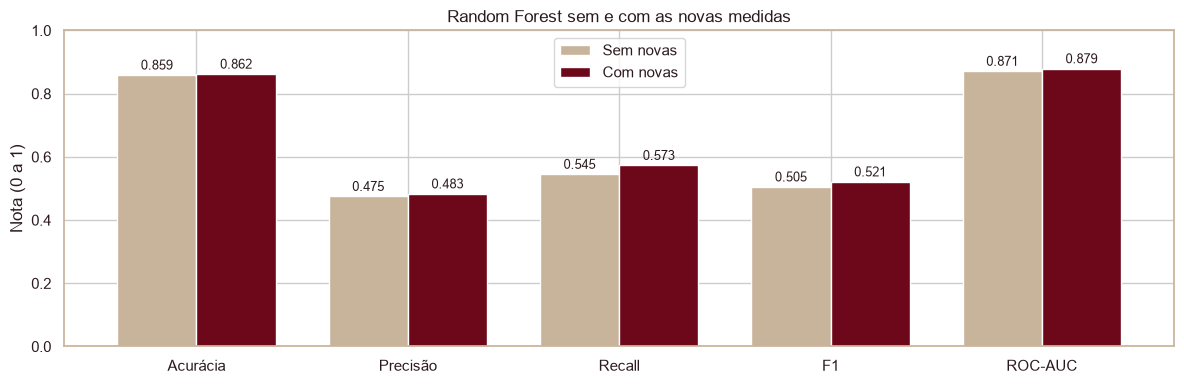

In [29]:
rf = {"Random Forest": modelos["Random Forest"]}
sem_novas = avaliar_cv(rf, X_treino.drop(columns=NOVAS), y_treino)[0]
com_novas = avaliar_cv(rf, X_treino, y_treino)[0]
efeito = pd.concat([sem_novas, com_novas], keys=["Sem novas", "Com novas"])
efeito = efeito.droplevel(1)

fig, ax = plt.subplots(figsize=(12, 4))
efeito.T.plot.bar(color=[CORTICA, BORDO], ax=ax, rot=0, width=0.75)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=9)
ax.set(title="Random Forest sem e com as novas medidas", ylim=(0, 1),
       ylabel="Nota (0 a 1)")
plt.tight_layout()

efeito

**O que isso significa:** com as 3 novas medidas, a Random Forest melhorou em **todas as métricas**: O maior ganho foi no **recall** (de 54,5% para 57,3% dos vinhos de alta qualidade encontrados). O ganho é pequeno, mas aparece em todas as métricas ao mesmo tempo. Por isso as novas medidas foram mantidas.

### 4.2 Ajuste fino dos modelos
Cada modelo tem "parâmetros" de configuração. Testamos várias combinações, sempre com a validação cruzada, e ficamos com a que **melhor separa os vinhos de alta qualidade dos que tem média/baixa qualidade** (maior ROC-AUC).

In [30]:
grids = {
    "Regressão Logística": {"logisticregression__C": [0.001, 0.01, 0.1, 1]},
    "SVM": {
        "svc__C": [0.01, 0.1, 1, 10],
        "svc__gamma": ["scale", 0.01, 0.1],
    },
    "Random Forest": {
        "max_depth": [None, 8, 12],
        "min_samples_leaf": [1, 3, 5],
        "max_features": ["sqrt", 0.5],
    },
}

otimizados, buscas = {}, {}
for nome, grid in grids.items():
    busca = GridSearchCV(modelos[nome], grid, scoring="roc_auc", cv=cv,
                         n_jobs=-1)
    busca.fit(X_treino, y_treino)
    otimizados[nome], buscas[nome] = busca.best_estimator_, busca
    print(f"{nome:20s} ROC-AUC={busca.best_score_:.3f} {busca.best_params_}")

Regressão Logística  ROC-AUC=0.888 {'logisticregression__C': 0.1}
SVM                  ROC-AUC=0.887 {'svc__C': 0.1, 'svc__gamma': 0.01}
Random Forest        ROC-AUC=0.884 {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}


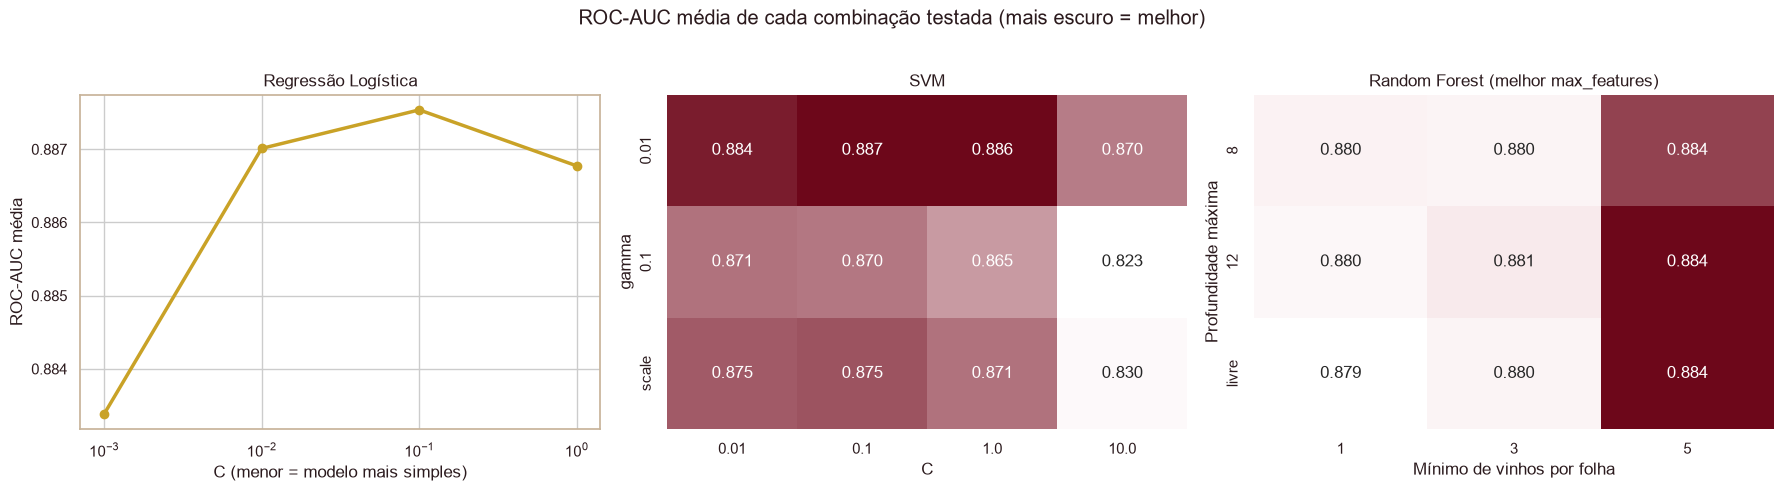

In [31]:
def resultados_busca(nome):
    """Tabela com os parâmetros testados e a ROC-AUC média."""
    res = pd.DataFrame(buscas[nome].cv_results_)
    return res.rename(columns={"mean_test_score": "ROC-AUC"})


fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

lr = resultados_busca("Regressão Logística")
ax[0].plot(lr["param_logisticregression__C"].astype(float), lr["ROC-AUC"],
           marker="o", color=DOURADO, lw=2.5)
ax[0].set(xscale="log", title="Regressão Logística",
          xlabel="C (menor = modelo mais simples)", ylabel="ROC-AUC média")

svm = resultados_busca("SVM")
svm["gamma"] = svm["param_svc__gamma"].astype(str)
tab_svm = svm.pivot_table(index="gamma", columns="param_svc__C",
                          values="ROC-AUC")
sns.heatmap(tab_svm, annot=True, fmt=".3f", cmap=CMAP_SEQ, cbar=False,
            ax=ax[1])
ax[1].set(title="SVM", xlabel="C", ylabel="gamma")

rf_res = resultados_busca("Random Forest")
rf_res["profundidade"] = rf_res["param_max_depth"].fillna("livre")
rf_res["profundidade"] = rf_res["profundidade"].astype(str)
tab_rf = rf_res.pivot_table(index="profundidade",
                            columns="param_min_samples_leaf",
                            values="ROC-AUC", aggfunc="max")
tab_rf = tab_rf.reindex(["8", "12", "livre"])
sns.heatmap(tab_rf, annot=True, fmt=".3f", cmap=CMAP_SEQ, cbar=False,
            ax=ax[2])
ax[2].set(title="Random Forest (melhor max_features)",
          xlabel="Mínimo de vinhos por folha", ylabel="Profundidade máxima")
fig.suptitle("ROC-AUC média de cada combinação testada (mais escuro = "
             "melhor)", y=1.02)
plt.tight_layout()

**O que isso significa**
- **Regressão Logística:** o melhor resultado veio com `C = 0,1` (ROC-AUC de 0,888). Um modelo simples demais (`C = 0,001`) perde um pouco de nota.
- **SVM:** as combinações com `C = 10` (fronteira muito ajustada ao treino) são as piores, com ROC-AUC entre 0,82 e 0,87. O melhor ficou em `C = 0,1` e `gamma = 0,01`, com ROC-AUC de 0,887.
- **Random Forest:** todas as combinações ficam entre 0,879 e 0,884. Demonstrando que o modelo é **robusto** e não depende de uma configuração muito específica. O melhor exige pelo menos 5 vinhos em cada "folha" da árvore, o que evita regras baseadas em casos isolados.

### 4.3 Ponto de corte
O modelo dá a cada vinho uma **chance de ser bom**, de 0 a 1. O padrão é chamar de "bom" quando a chance passa de 0,5, mas esse corte nem sempre é o melhor. Escolhemos, para cada modelo, o corte que melhor equilibra **encontrar os vinhos de alta qualidade** e **evitar falsos positivos** (maior F1), usando só os dados de treino.

Regressão Logística    0.68
SVM                    0.34
Random Forest          0.57
Name: ponto de corte, dtype: float64

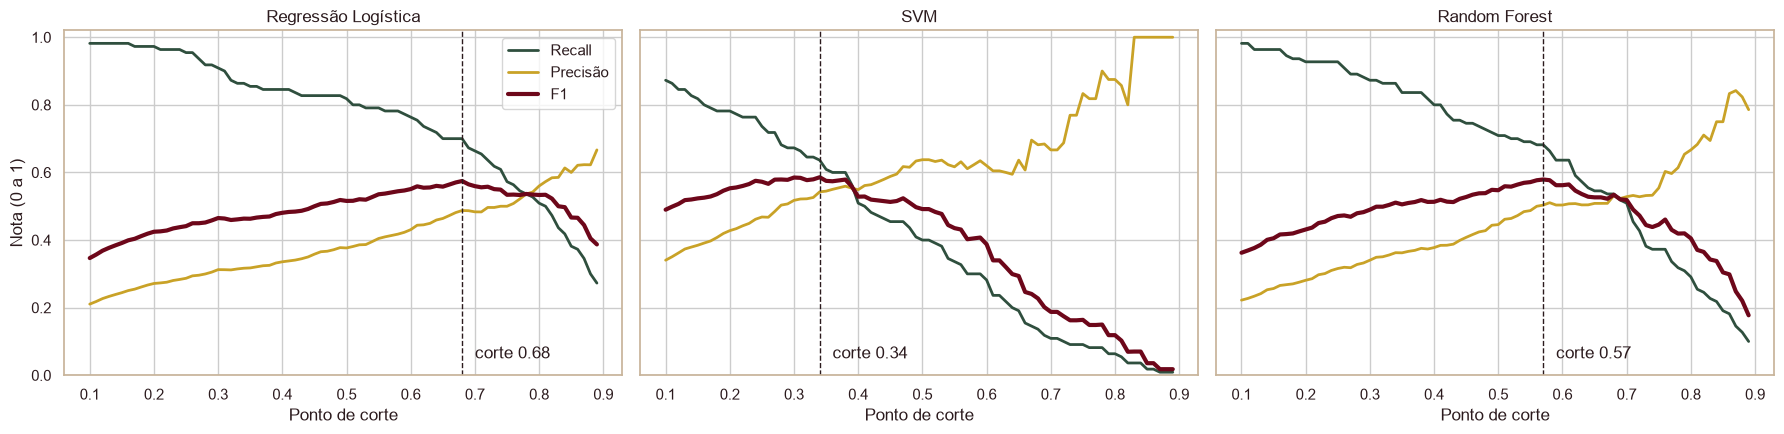

In [32]:
GRADE = np.arange(0.10, 0.90, 0.01)
limiares, curvas = {}, {}
for nome, modelo in otimizados.items():
    proba = cross_val_predict(modelo, X_treino, y_treino, cv=cv,
                              method="predict_proba")[:, 1]
    curvas[nome] = pd.DataFrame({
        "Recall": [recall_score(y_treino, proba >= t) for t in GRADE],
        "Precisão": [precision_score(y_treino, proba >= t, zero_division=0)
                     for t in GRADE],
        "F1": [f1_score(y_treino, proba >= t) for t in GRADE],
    }, index=GRADE)
    limiares[nome] = curvas[nome]["F1"].idxmax()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
cores_curvas = {"Recall": VERDE_GARRAFA, "Precisão": DOURADO, "F1": BORDO}
for eixo, (nome, tabela) in zip(ax, curvas.items()):
    for metrica, cor in cores_curvas.items():
        eixo.plot(tabela.index, tabela[metrica], color=cor, label=metrica,
                  lw=3 if metrica == "F1" else 2)
    eixo.axvline(limiares[nome], color=TEXTO, ls="--", lw=1)
    eixo.text(limiares[nome] + 0.02, 0.05, f"corte {limiares[nome]:.2f}",
              color=TEXTO)
    eixo.set(title=nome, xlabel="Ponto de corte", ylim=(0, 1.02))
ax[0].set_ylabel("Nota (0 a 1)")
ax[0].legend(loc="upper right")
plt.tight_layout()

pd.Series(limiares, name="ponto de corte").round(2)

**O que isso significa:** subir o corte deixa o modelo mais exigente: ele acerta mais quando aponta (precisão sobe), mas encontra menos vinhos bons (recall cai). A linha tracejada marca o ponto de equilíbrio (maior F1).
- A Random Forest funciona melhor com um corte de **0,57**, um pouco acima do padrão de 0,5.
- A Regressão Logística, que aponta vinhos demais, funciona melhor com um corte **mais alto (0,68)**, para ficar mais exigente.
- O SVM tem um corte mais baixo (**0,34**) porque as chances que ele calcula ficam naturalmente menores. O que importa é a **ordem** dos vinhos; o corte só ajusta a escala.

# Etapa 5 – Avaliação dos modelos (conjunto de teste)

Agora usamos os **204 vinhos separados para teste**, que nenhum modelo viu antes. É a simulação mais próxima do uso real.

In [33]:
def metricas_teste(pred, proba):
    """Métricas de um modelo no conjunto de teste."""
    return {
        "Acurácia": accuracy_score(y_teste, pred),
        "Precisão": precision_score(y_teste, pred, zero_division=0),
        "Recall": recall_score(y_teste, pred),
        "F1": f1_score(y_teste, pred),
        "ROC-AUC": roc_auc_score(y_teste, proba),
    }


referencia = modelos["Referência"].fit(X_treino, y_treino)
proba_ref = referencia.predict_proba(X_teste)[:, 1]
linhas = {"Referência": metricas_teste(referencia.predict(X_teste),
                                       proba_ref)}
probas = {}
for nome, modelo in otimizados.items():
    modelo.fit(X_treino, y_treino)
    probas[nome] = modelo.predict_proba(X_teste)[:, 1]
    linhas[nome] = metricas_teste(probas[nome] >= limiares[nome],
                                  probas[nome])

resultados = pd.DataFrame(linhas).T.round(3)
resultados.sort_values("ROC-AUC", ascending=False)

,Acurácia,Precisão,Recall,F1,ROC-AUC
Random Forest,0.853,0.462,0.667,0.545,0.912
SVM,0.863,0.485,0.593,0.533,0.893
Regressão Logística,0.843,0.432,0.593,0.500,0.885
Referência,0.868,0.000,0.000,0.000,0.500


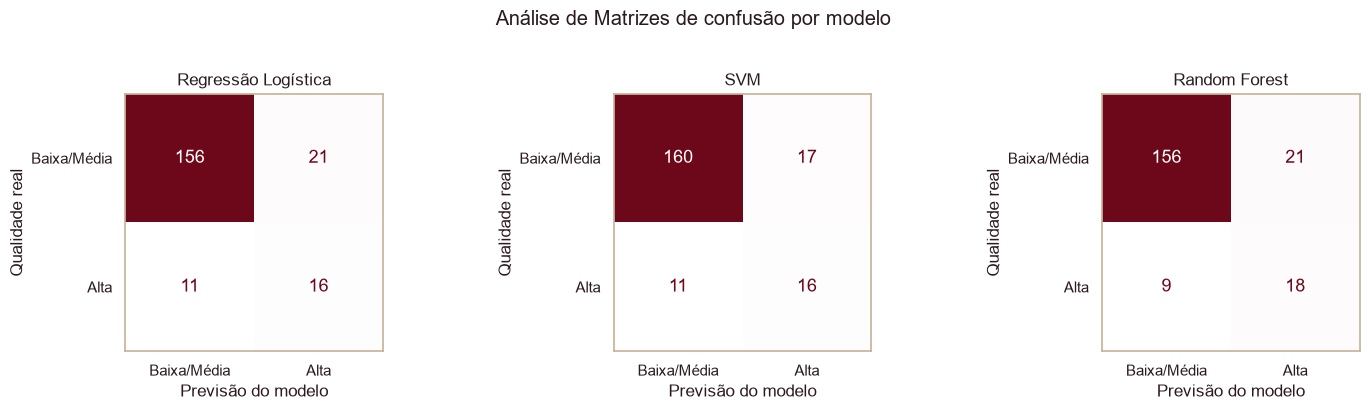

In [34]:

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for eixo, (nome, proba) in zip(ax, probas.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_teste, proba >= limiares[nome],
        display_labels=["Baixa/Média", "Alta"],
        cmap=CMAP_SEQ, colorbar=False, ax=eixo,
        text_kw={"fontsize": 13},
    )
    fig.suptitle("Análise de Matrizes de confusão por modelo", y=1.02)
    eixo.set_title(nome)
    eixo.set_xlabel("Previsão do modelo")
    eixo.set_ylabel("Qualidade real")
    eixo.grid(False)
plt.tight_layout()

Cada quadro compara **o que o vinho realmente era** (linhas) com **o que o modelo disse** (colunas):

**Comparando os três modelos:**

| Modelo | Vinhos bons encontrados (de 27) | Vinhos bons que deixou passar | Alarmes falsos (de 177) |
|---|---|---|---|
| **Random Forest** | **18** | **9** | 21 |
| SVM | 16 | 11 | **17** |
| Regressão Logística | 16 | 11 | 21 |

**O que isso significa:** a Random Forest é a que **mais encontra vinhos de alta qualidade** (18) e a que menos deixa passar. O SVM erra menos ao apontar um vinho como bom (17 alarmes falsos), mas encontra 2 vinhos bons a menos. Como o objetivo é **encontrar os vinhos de alta qualidade**, a Random Forest é a melhor escolha.

**Curva ROC e métricas no teste:** quanto mais a curva se aproxima do canto superior esquerdo, melhor o modelo separa vinhos bons de comuns. A linha tracejada representa um chute aleatório (AUC = 0,5). À direita, todas as métricas lado a lado, incluindo a referência.

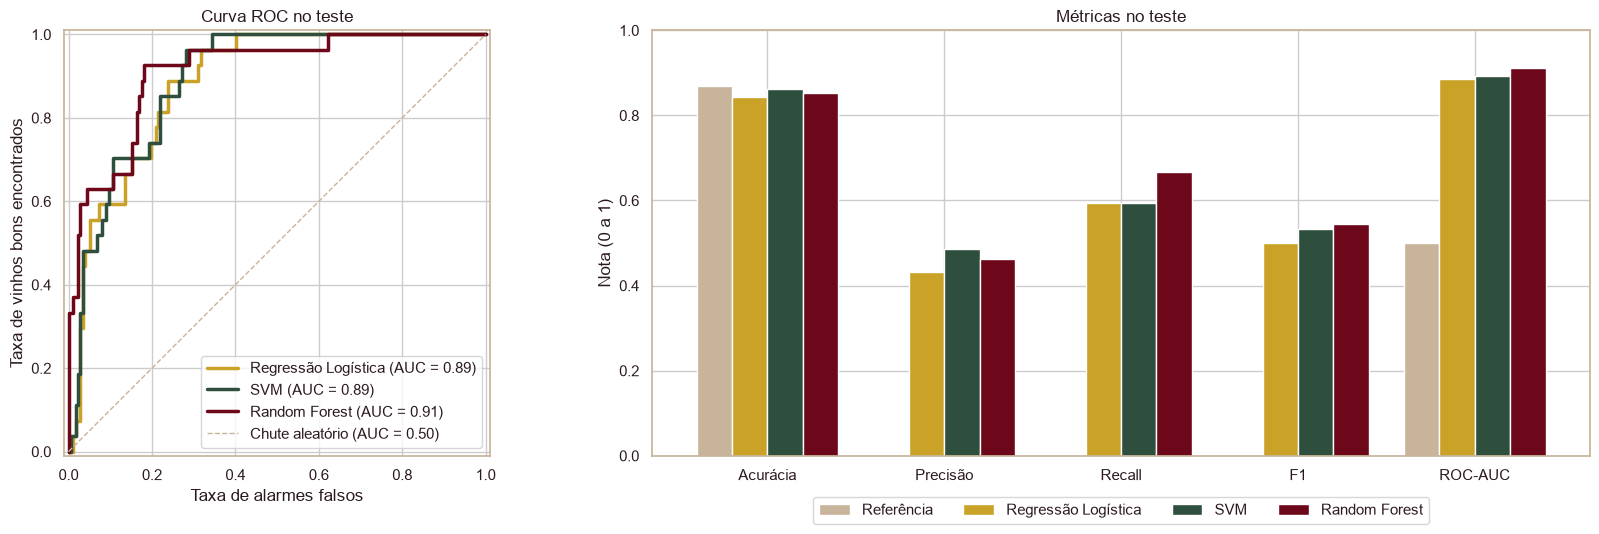

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5),
                       gridspec_kw={"width_ratios": [1, 1.4]})
for nome, proba in probas.items():
    estilo = {"color": CORES_MODELOS[nome], "lw": 2.5}
    RocCurveDisplay.from_predictions(y_teste, proba, name=nome,
                                     curve_kwargs=estilo, ax=ax[0])
ax[0].plot([0, 1], [0, 1], color=CORTICA, ls="--", lw=1,
           label="Chute aleatório (AUC = 0.50)")
ax[0].set(title="Curva ROC no teste", xlabel="Taxa de alarmes falsos",
          ylabel="Taxa de vinhos bons encontrados")
ax[0].legend(loc="lower right")

CORES_TESTE = {"Referência": CORTICA, **CORES_MODELOS}
resultados.T.plot.bar(color=[CORES_TESTE[m] for m in resultados.index],
                      ax=ax[1], rot=0, width=0.8)
ax[1].set(title="Métricas no teste", ylim=(0, 1), ylabel="Nota (0 a 1)")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
plt.tight_layout()

**Validação cruzada x teste:** se o modelo tivesse apenas "decorado" o treino, a nota no teste cairia muito em relação à validação cruzada.

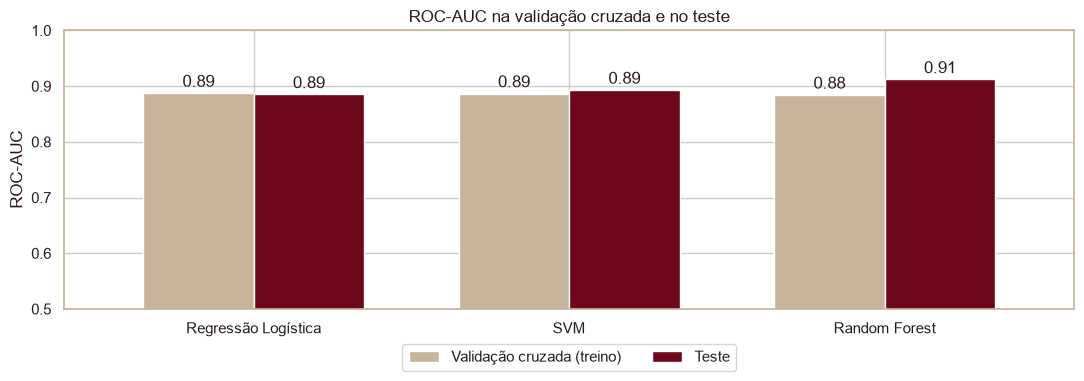

In [36]:
validacao = pd.Series({nome: b.best_score_ for nome, b in buscas.items()})
comparacao = pd.DataFrame({
    "Validação cruzada (treino)": validacao,
    "Teste": resultados.loc[validacao.index, "ROC-AUC"],
})

fig, ax = plt.subplots(figsize=(11, 4))
comparacao.plot.bar(color=[CORTICA, BORDO], ax=ax, rot=0, width=0.7)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", padding=2)
ax.set(title="ROC-AUC na validação cruzada e no teste", ylim=(0.5, 1),
       ylabel="ROC-AUC")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.tight_layout()

**O que isso significa** (no teste há 27 vinhos bons entre 204; com números tão pequenos, 1 ou 2 acertos já mudam bastante as porcentagens):
- A **Random Forest** teve a maior ROC-AUC (**0,91**), o maior recall e o maior F1. Ela encontrou **18 dos 27 vinhos bons** (2 de cada 3). Quando aponta um vinho de alta qualidade, acerta em **46%** das vezes, um bom resultado já que só 13% dos vinhos são de alta qualidade.
- O **SVM** ficou perto (ROC-AUC 0,89): encontrou 16 vinhos bons e deu menos alarmes falsos (17 contra 21), por isso tem precisão e acurácia um pouco maiores.
- A **Regressão Logística** também encontrou 16 vinhos de alta qualidade, mas com 21 alarmes falsos.
- **Acurácia:** a referência tem a maior acurácia do teste (86,8%) sem encontrar nenhum vinho bom. Isso confirma que a acurácia sozinha não serve para escolher o modelo aqui.
- **Validação x teste:** a ROC-AUC no teste ficou praticamente igual à da validação cruzada (diferenças de até 0,03). Os modelos **aprenderam padrões reais**, e não apenas "decoraram" os dados.

**Modelo escolhido: Random Forest** (maior ROC-AUC, recall e F1 no teste).

# Etapa 6 – Interpretação dos resultados

### 6.1 Quais medidas mais influenciam a qualidade?
- **Gráfico da esquerda (Random Forest):** mostra quanto o modelo piora quando "embaralhamos" cada medida. Quanto maior a barra, mais o modelo depende dela.
- **Gráfico da direita (Regressão Logística):** mostra a direção do efeito. Barras **bordô** aumentam a chance de alta qualidade e barras **verde-garrafa** reduzem.

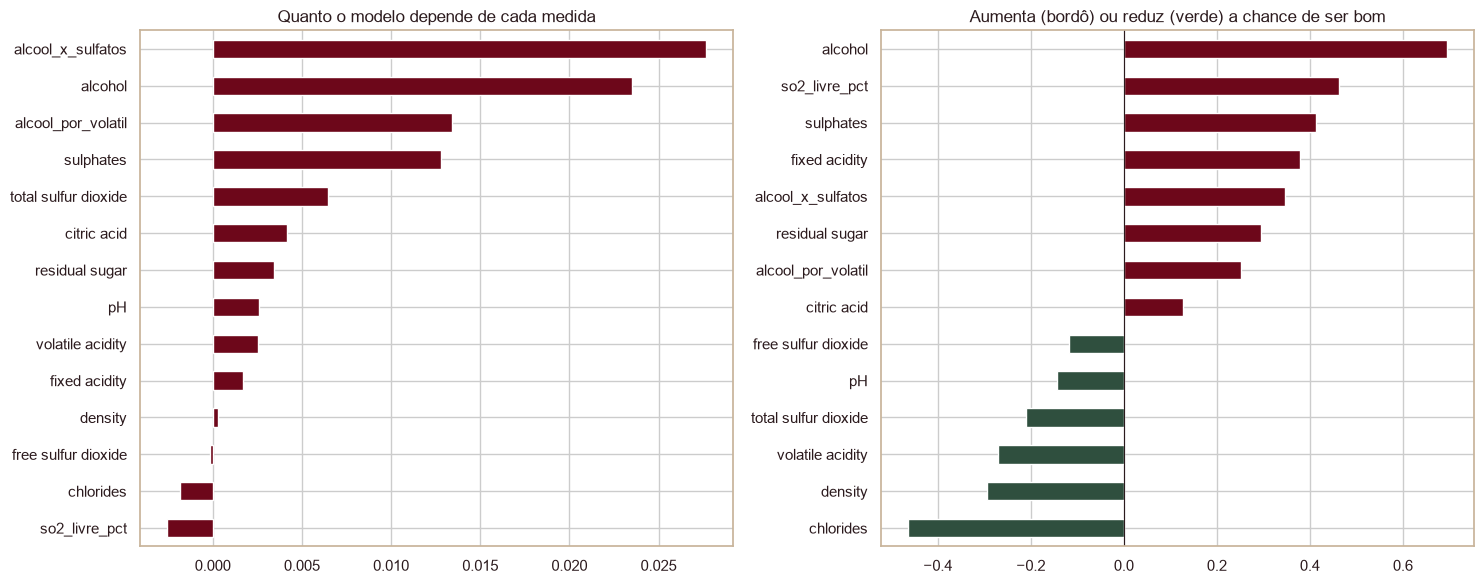

In [37]:
rf_final = otimizados["Random Forest"]
lr_final = otimizados["Regressão Logística"]

perm = permutation_importance(rf_final, X_teste, y_teste,
                              scoring="roc_auc", n_repeats=30,
                              random_state=SEED)
importancia = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
coef = pd.Series(lr_final[-1].coef_[0],
                 index=lr_final[0].get_feature_names_out()).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
importancia.plot.barh(ax=ax[0], color=BORDO)
ax[0].set_title("Quanto o modelo depende de cada medida")
coef.plot.barh(ax=ax[1], color=np.where(coef > 0, BORDO, VERDE_GARRAFA))
ax[1].axvline(0, color=TEXTO, lw=0.8)
ax[1].set_title("Aumenta (bordô) ou reduz (verde) a chance de ser bom")
plt.tight_layout()

O gráfico abaixo mostra como a **chance de um vinho ser bom** muda conforme cada medida aumenta, mantendo as demais iguais.

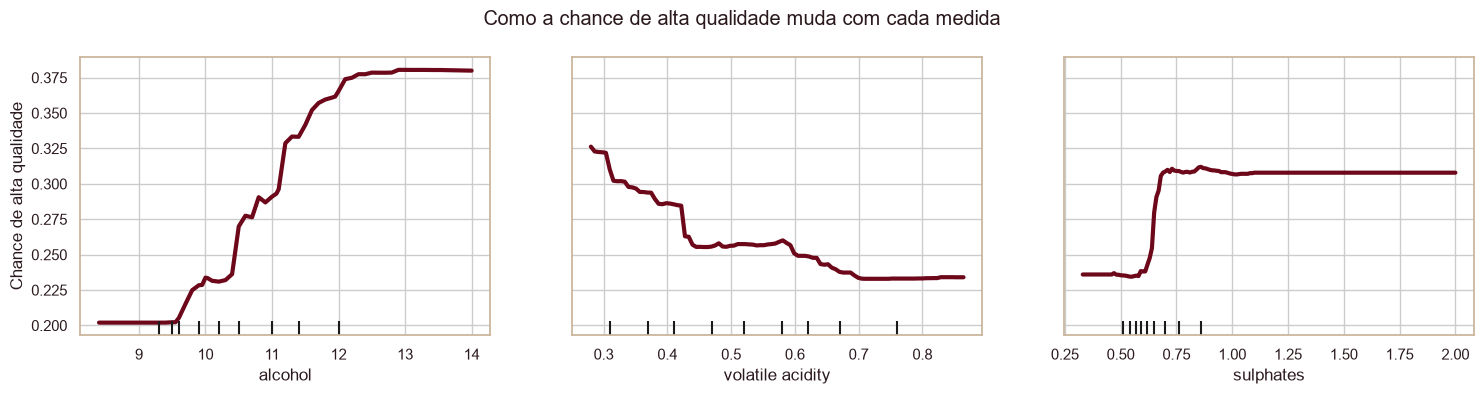

In [38]:
pdp = PartialDependenceDisplay.from_estimator(
    rf_final, X_treino, ["alcohol", "volatile acidity", "sulphates"],
    n_cols=3, line_kw={"color": BORDO, "lw": 3},
)
pdp.axes_[0, 0].set_ylabel("Chance de alta qualidade")
fig = plt.gcf()
fig.set_size_inches(15, 4)
fig.suptitle("Como a chance de alta qualidade muda com cada medida")
plt.tight_layout()

**O que isso significa**
1. **O álcool é o fator mais forte.** A chance de alta qualidade **quase dobra** (de cerca de 20% para quase 40%) quando o álcool passa de 9,5% para 12,5%, e depois para de crescer. Ele aparece no topo dos dois modelos, sozinho e combinado com os sulfatos.
2. **Os sulfatos ajudam até certo ponto.** A chance sobe bastante entre 0,60 e 0,70; acima disso não há ganho.
3. **A acidez volátil prejudica.** Quanto menos "vinagre", melhor, principalmente abaixo de 0,4. Na Random Forest ela aparece com peso quase zero porque o efeito dela já está dentro da medida "álcool ÷ acidez volátil", uma das mais importantes.
4. **Cloretos (sal) e excesso de SO₂** reduzem a chance de alta qualidade.
5. pH, densidade e SO₂ livre quase não influenciam.

Os dois modelos, que funcionam de formas bem diferentes, chegam às **mesmas conclusões** da análise exploratória. Isso aumenta a confiança nos resultados.

### 6.2 Implicações para o processo de produção
- **Controlar a acidez volátil é prioridade.** É o principal defeito que dá para medir. Higiene na vinícola, uvas sadias, controle de temperatura e menos contato com oxigênio ajudam. Medir durante a fermentação permite **corrigir o problema antes de engarrafar**.
- **Colher a uva no ponto certo.** Uvas maduras geram mais álcool e mais corpo, o que está ligado a notas mais altas.
- **Conservantes na medida certa.** Os sulfatos protegem o vinho, mas a partir de certo nível não trazem ganho. Já o excesso de SO₂ total está ligado a notas mais baixas.
- **Uso prático do modelo:** fazer uma triagem dos lotes no laboratório. Os lotes com maior chance de serem considerados de alta qualidade podem ir para linhas premium, e só os casos duvidosos vão para a degustação de especialistas, **economizando tempo e custo**.

# Etapa 7 – Conclusões e limitações

**Conclusões**
- É possível identificar vinhos de alta qualidade **com dados de caracteristicas fisico-quimicas dos vinhos**: o modelo final encontrou 2 de cada 3 vinhos considerados de alta qualidade, com ROC-AUC de 0,91.
- A **Random Forest** foi o melhor modelo, seguida de perto pelo **SVM**.
- **Álcool, sulfatos e acidez volátil** são os fatores que mais pesam na qualidade.

**Limitações**
- Há poucos vinhos considerados de alta qualidade na base (137), então os resultados do teste dependem de poucos casos.
- A base tem apenas vinhos tintos de uma mesma região; o modelo pode não funcionar para outros estilos.
- A nota é dada por pessoas e tem um lado subjetivo. O corte em 7 também é uma escolha.
- Faltam informações importantes, como tipo de uva, safra e tempo em barril.

**Próximos passos:** reunir mais exemplos de vinhos considerados de alta qualidade, testar outros modelos e validar o modelo com lotes reais da produção.